In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import zipfile
import os
from tqdm.notebook import tqdm

zip_path = "/content/drive/MyDrive/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3.zip"

# Extract inside Colab runtime storage
extract_path = "/content/PTBXL"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:

    files = zip_ref.infolist()

    print(f"Total files: {len(files)}")

    for file in tqdm(files, desc="Extracting"):
        zip_ref.extract(file, extract_path)

print("Extraction completed!")

Total files: 43636


Extracting:   0%|          | 0/43636 [00:00<?, ?it/s]

Extraction completed!


In [3]:
!pip install wfdb pandas numpy scipy scikit-learn matplotlib seaborn tqdm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 6.8 MB/s eta 0:00:00


In [4]:
import os
import ast
import gc
import random
import warnings
from collections import Counter
import matplotlib.pyplot as plt

import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from scipy.signal import butter, sosfiltfilt, iirnotch, tf2sos
from sklearn.preprocessing import MultiLabelBinarizer, StandardScaler
from tqdm.auto import tqdm
import wfdb

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)
try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass

In [5]:
class Config:
    DATA_PATH = "/content/PTBXL/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3"


    SAMPLING_RATE = 100
    SIGNAL_DURATION_SEC = 10
    SIGNAL_LENGTH = SAMPLING_RATE * SIGNAL_DURATION_SEC

    NUM_LEADS = 12
    LEAD_NAMES = ['I','II','III','aVR','aVL','aVF','V1','V2','V3','V4','V5','V6']

    BANDPASS_LOW  = 0.5
    BANDPASS_HIGH = 40.0
    BANDPASS_ORDER = 4

    NOTCH_FREQS = [50.0]
    NOTCH_Q = 30.0

    RARE_CLASS_THRESHOLD = 50

    TRAIN_FOLDS = [1, 2, 3, 4, 5, 6, 7, 8]
    VAL_FOLD    = 9
    TEST_FOLD   = 10


    AUG_PROB = 0.5
    AUG_GAUSSIAN_NOISE_STD = 0.05
    AUG_AMPLITUDE_SCALE_RANGE = (0.9, 1.1)
    AUG_TIME_SHIFT_MAX = 100
    AUG_LEAD_DROPOUT_PROB = 0.2
    AUG_LEAD_DROPOUT_MAX_LEADS = 2

    BATCH_SIZE = 32


cfg = Config()

print("=" * 60)
print("PTB-XL Preprocessing Pipeline")
print("=" * 60)
print(f"Data path  : {cfg.DATA_PATH}")
print(f"Sample rate: {cfg.SAMPLING_RATE} Hz")
print(f"Signal len : {cfg.SIGNAL_LENGTH} samples (10 s)")
print(f"Leads      : {cfg.NUM_LEADS}")

PTB-XL Preprocessing Pipeline
Data path  : /content/PTBXL/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3
Sample rate: 100 Hz
Signal len : 1000 samples (10 s)
Leads      : 12


In [6]:

# ============================================================
# 2. Load metadata + raw signals
# ============================================================
def load_ptbxl_metadata(data_path):
    print("\n[1/8] Loading PTB-XL metadata ...")
    meta_path = os.path.join(data_path, "ptbxl_database.csv")
    df = pd.read_csv(meta_path, index_col="ecg_id")
    df["scp_codes"] = df["scp_codes"].apply(ast.literal_eval)
    scp_df = pd.read_csv(os.path.join(data_path, "scp_statements.csv"), index_col=0)
    print("Total records:", len(df))
    return df, scp_df


def load_raw_signals(df, data_path, sampling_rate):

    print("\n[2/8] Loading ECG using memory map ...")
    filename_col = "filename_lr" if sampling_rate == 100 else "filename_hr"

    paths = df[filename_col].apply(lambda x: os.path.join(data_path, x)).tolist()

    X = np.memmap(
        "/content/X_raw.dat",
        dtype=np.float32,
        mode="w+",
        shape=(len(paths), cfg.SIGNAL_LENGTH, cfg.NUM_LEADS),
    )

    for i, path in enumerate(tqdm(paths, desc="Reading ECG")):
        signal = wfdb.rdsamp(path)[0]
        X[i] = signal.astype(np.float32)

    print("ECG shape:", X.shape)
    return X


df_meta, scp_df = load_ptbxl_metadata( cfg.DATA_PATH )

X_raw = load_raw_signals( df_meta, cfg.DATA_PATH, cfg.SAMPLING_RATE )



[1/8] Loading PTB-XL metadata ...
Total records: 21799

[2/8] Loading ECG using memory map ...


Reading ECG:   0%|          | 0/21799 [00:00<?, ?it/s]

ECG shape: (21799, 1000, 12)



[2/7] Removing unlabelled and rare class records ...
  Before filtering: 21799 records
  After removing unlabelled: 21388 records
  After removing missing age/sex: 21388 records
  Class distribution before rare removal: {'NORM': 9514, 'MI': 5469, 'STTC': 5235, 'HYP': 2649, 'CD': 4898}
  No rare classes found.
  Final class distribution: {'NORM': 9514, 'MI': 5469, 'STTC': 5235, 'HYP': 2649, 'CD': 4898}
Remaining: 21388


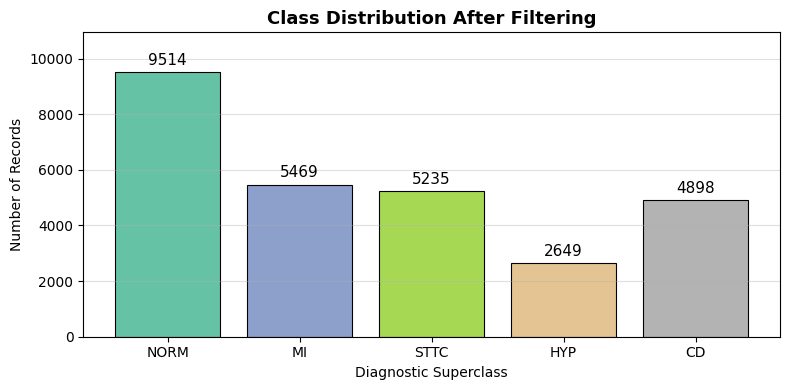

In [7]:
def aggregate_diagnostic_superclass(df, scp_df):
    diag_scp = scp_df[scp_df["diagnostic"] == 1.0]
    code_to_class = diag_scp["diagnostic_class"].to_dict()

    def get_labels(scp_dict):
        return {code_to_class[c] for c, lh in scp_dict.items()
                if lh >= 0 and c in code_to_class and pd.notna(code_to_class[c])}

    df = df.copy()
    df["labels"] = df["scp_codes"].apply(get_labels)
    return df


def remove_unlabelled_and_rare(df, X, threshold=50):
    print("\n[2/7] Removing unlabelled and rare class records ...")
    print(f"  Before filtering: {len(df)} records")

    # -----------------------------------
    # 1. Remove unlabelled ECGs

    mask = df["labels"].apply(len) > 0
    df = df[mask]
    print(f"  After removing unlabelled: {len(df)} records")

    # -------------------------------------------------------------
    # 2. Remove records with missing demographics

    mask = (df["age"].notna() & df["sex"].notna())
    df = df[mask]
    print(f"  After removing missing age/sex: {len(df)} records")

    # -------------------------------------------------------------
    # 3. Continue with rare class removal

    label_counts = Counter(lbl for s in df["labels"] for lbl in s)
    print(f"  Class distribution before rare removal: {dict(label_counts)}")

    rare_classes = {c for c, n in label_counts.items() if n < threshold}

    if rare_classes:
        print(f"  Rare classes (< {threshold} samples): {rare_classes}")

        df["labels"] = df["labels"].apply(lambda s: {l for l in s if l not in rare_classes})
        df = df[df["labels"].apply(len) > 0]

        print(f"  After removing rare-only records: {len(df)} records")
    else:
        print("  No rare classes found.")


    # keep only selected indexes
    selected_idx = df.index.values
    X_filtered_view = X[ df_meta.index.get_indexer( selected_idx ) ]
    label_counts = Counter(lbl for s in df["labels"] for lbl in s)

    print(f"  Final class distribution: {dict(label_counts)}")
    print( "Remaining:", len(df) )

    return df.reset_index(drop=False), X_filtered_view, label_counts


df_meta = aggregate_diagnostic_superclass(df_meta, scp_df)
df_meta, X_raw, label_counts = remove_unlabelled_and_rare(df_meta, X_raw, cfg.RARE_CLASS_THRESHOLD)


def plot_class_distribution(label_counts, title="Class Distribution After Filtering"):
    fig, ax = plt.subplots(figsize=(8, 4))
    classes, counts = list(label_counts.keys()), list(label_counts.values())
    colors = plt.cm.Set2(np.linspace(0, 1, len(classes)))
    bars = ax.bar(classes, counts, color=colors, edgecolor='black', linewidth=0.8)
    ax.bar_label(bars, fmt='%d', padding=3, fontsize=11)
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.set_xlabel("Diagnostic Superclass"); ax.set_ylabel("Number of Records")
    ax.set_ylim(0, max(counts) * 1.15)
    ax.grid(axis='y', alpha=0.4)
    plt.tight_layout()
    plt.savefig("viz_01_class_distribution.png", dpi=150)
    plt.show()

plot_class_distribution(label_counts)

In [8]:
# ============================================================
# Save ECG before preprocessing (for visualization only)
# ============================================================

sample_idx = 500       # choose any ECG record
lead_idx = 1           # Lead II

before_preprocess = X_raw[sample_idx, :, lead_idx].copy()

print("Before preprocessing saved")
print(before_preprocess.shape)

Before preprocessing saved
(1000,)


In [9]:
# ============================================================
# ECG Filtering: Butterworth Bandpass + Notch
# ============================================================

import numpy as np
import gc
from scipy.signal import butter, sosfiltfilt, iirnotch, tf2sos
from tqdm.auto import tqdm


def build_filters(fs, lowcut, highcut, order, notch_freqs, Q):
    nyq = 0.5 * fs

    # Bandpass filter
    sos_bp = butter(
        order,
        [lowcut / nyq, highcut / nyq],
         btype="band", output="sos" )

    # Notch filters
    notch_filters = [
        tf2sos(*iirnotch(freq, Q, fs=fs))
        for freq in notch_freqs
    ]

    return sos_bp, notch_filters


def apply_ecg_filters(X, fs, lowcut, highcut, order, notch_freqs, Q):
    print("\n[3/7] Applying ECG Filters")
    print(f"Bandpass : {lowcut}-{highcut} Hz")
    print(f"Notch    : {notch_freqs} Hz")
    print(f"Input    : {X.shape}")

    X = X.astype(np.float32, copy = False)

    sos_bp, notch_filters = build_filters(
        fs, lowcut, highcut, order, notch_freqs, Q
    )

    for i in tqdm(range(len(X)), desc="Filtering"):
        # Bandpass
        sig = sosfiltfilt( sos_bp, X[i], axis=0 )

        # Notch
        for notch in notch_filters:
            sig = sosfiltfilt( notch, sig, axis=0 )

        # Replace original ECG
        X[i] = sig.astype(np.float32)

        if i % 1000 == 0:
            gc.collect()

    print("Filtering complete")
    print("Output:", X.shape)

    return X


# =========================
# Run Filtering
# =========================

X_raw = apply_ecg_filters(
    X_raw,
    fs=cfg.SAMPLING_RATE,
    lowcut=cfg.BANDPASS_LOW,
    highcut=cfg.BANDPASS_HIGH,
    order=cfg.BANDPASS_ORDER,
    notch_freqs=cfg.NOTCH_FREQS,
    Q=cfg.NOTCH_Q
)


# =========================
# Save Filtered Data
# =========================

output_dir = "/content/drive/MyDrive/PTBXL/"
os.makedirs(output_dir, exist_ok=True)

np.save( os.path.join(output_dir, "X_filtered_500hz.npy"), X_raw )


# =========================
# Clean RAM
# =========================

del X_raw
gc.collect()

print("Saved and memory cleaned")


[3/7] Applying ECG Filters
Bandpass : 0.5-40.0 Hz
Notch    : [50.0] Hz
Input    : (21388, 1000, 12)


Filtering:   0%|          | 0/21388 [00:00<?, ?it/s]

Filtering complete
Output: (21388, 1000, 12)
Saved and memory cleaned


Filtered ECG shape: (21388, 1000, 12)
Disease ECG Example
Class: Myocardial Infarction (MI)
Index: 7
Label: {'MI'}


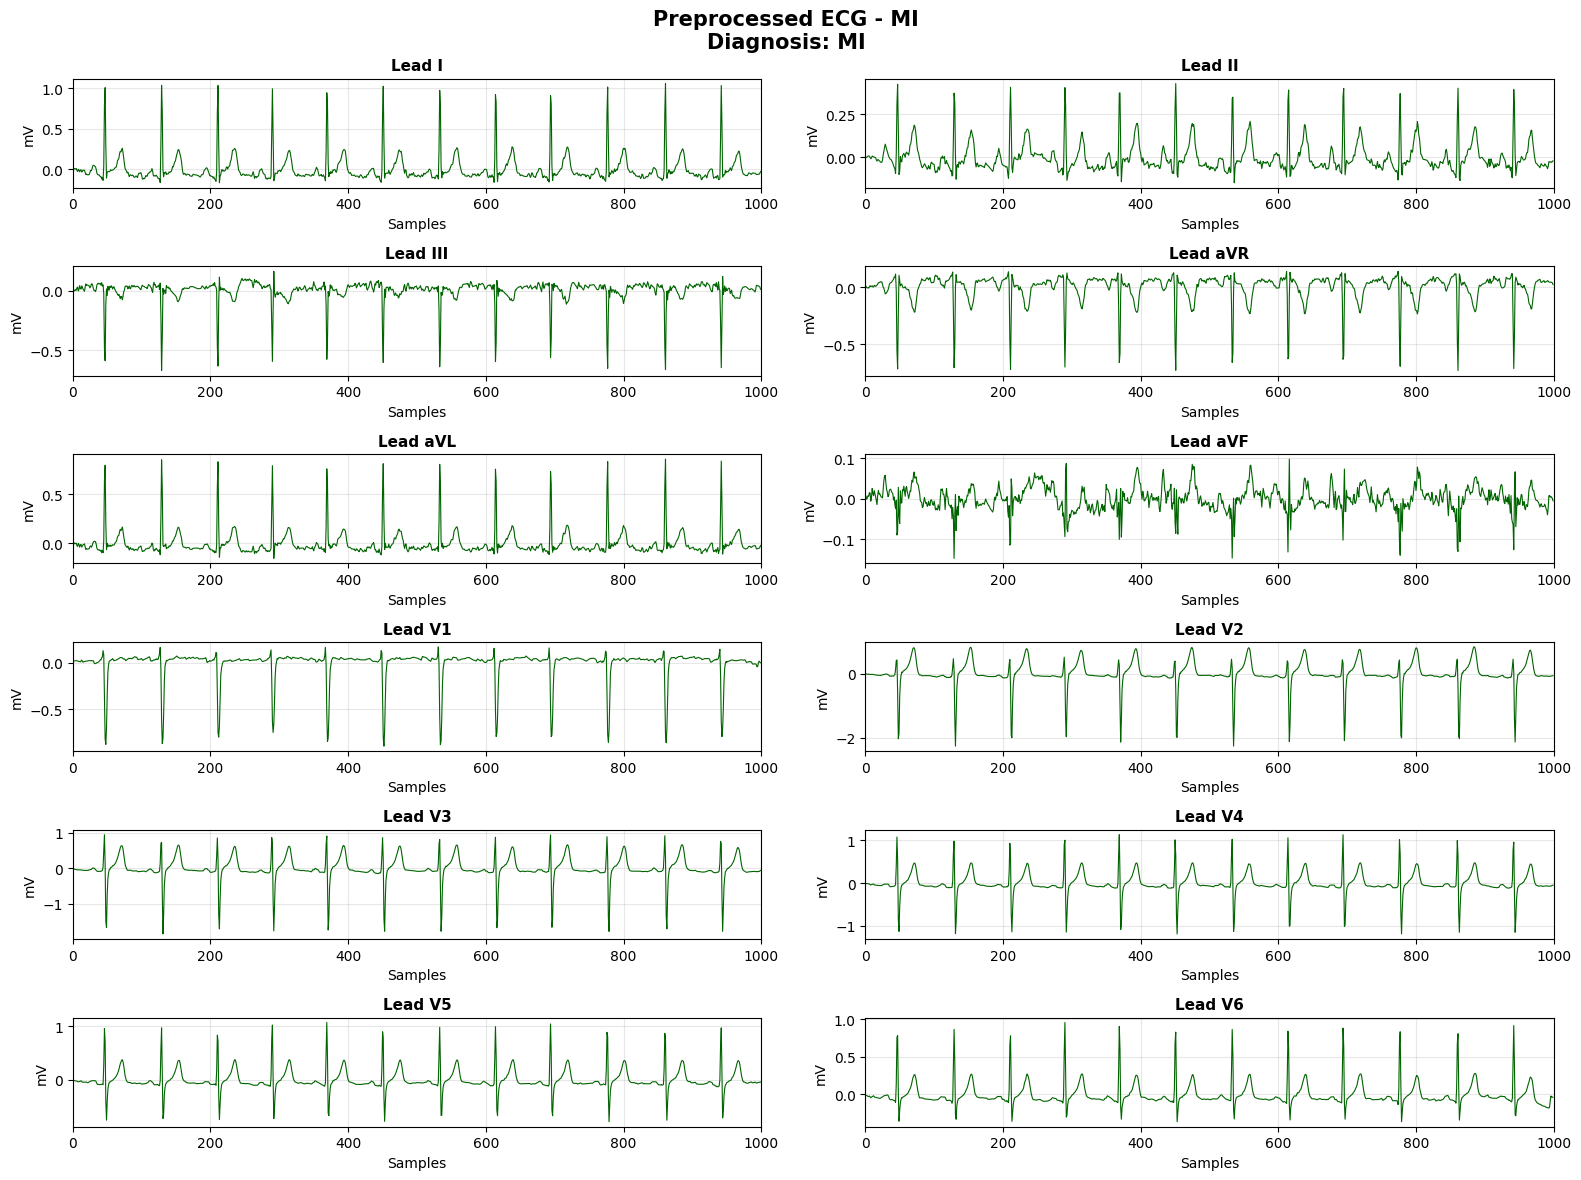

Normal ECG Example
Class: Normal
Index: 0
Label: {'NORM'}


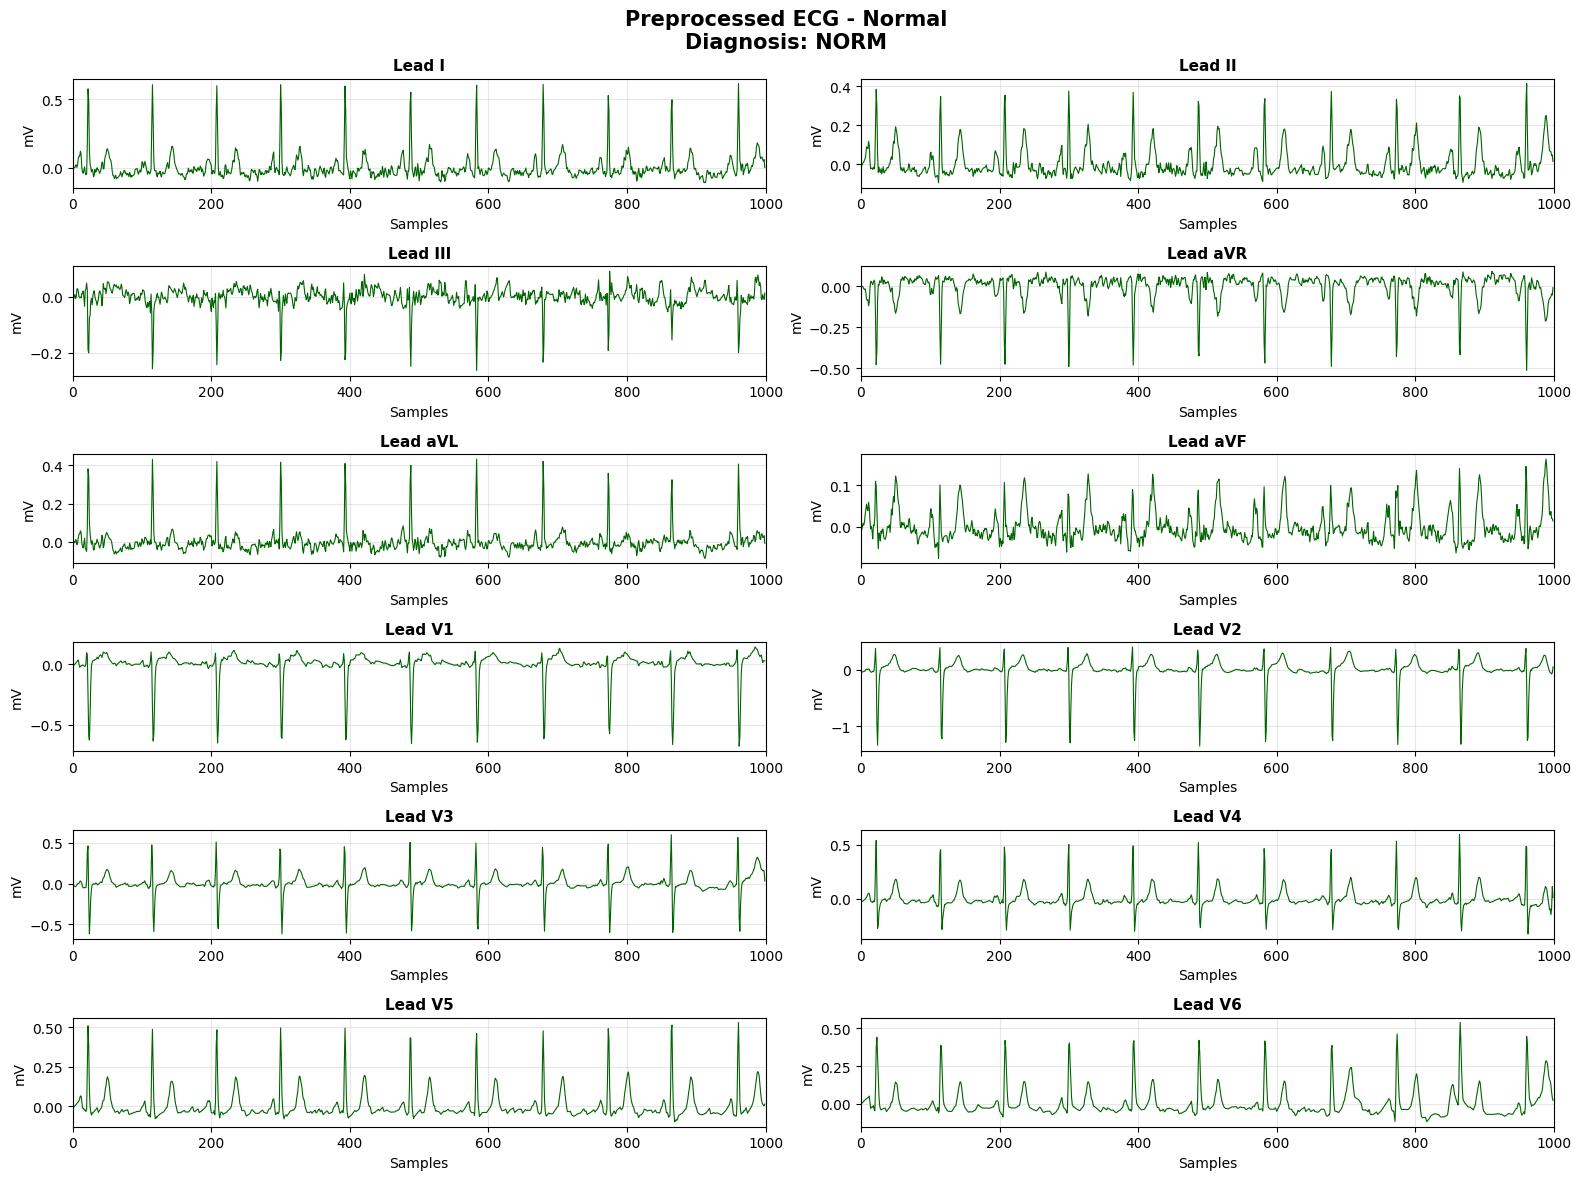

In [10]:
# ════════════════════════════════════════════════════════════════
# Visualize ECG After Preprocessing
# ════════════════════════════════════════════════════════════════

import matplotlib.pyplot as plt
import numpy as np
import os


# Load Preprocessed ECG
filtered_path = "/content/drive/MyDrive/PTBXL/X_filtered_500hz.npy"
X_filtered = np.load( filtered_path, mmap_mode="r" )    # saves RAM


print( "Filtered ECG shape:", X_filtered.shape )


# Plot Function
def plot_ecg(signal, labels, title="ECG Signal"):

    lead_names = [
        'I', 'II', 'III',
        'aVR', 'aVL', 'aVF',
        'V1', 'V2', 'V3',
        'V4', 'V5', 'V6'
    ]

    fig, axes = plt.subplots( 6, 2, figsize=(16,12) )

    axes = axes.flatten()

    for i in range(12):

        axes[i].plot( signal[:, i], linewidth=0.8, color="darkgreen" )
        axes[i].set_title( f"Lead {lead_names[i]}", fontsize=11, fontweight="bold" )
        axes[i].set_xlim( 0, signal.shape[0] )
        axes[i].set_xlabel( "Samples" )
        axes[i].set_ylabel( "mV" )
        axes[i].grid( alpha=0.3 )

    diagnosis = ", ".join( list(labels) )


    fig.suptitle(
        f"{title}\nDiagnosis: {diagnosis}",
        fontsize=15,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()


# =====================================================
# Disease ECG Example After Preprocessing (MI)
# =====================================================

mi_indices = np.where(
    df_meta["labels"].apply( lambda x: "MI" in x )
)[0]


if len(mi_indices) > 0:

    idx = mi_indices[0]

    print("="*50)
    print("Disease ECG Example")
    print("Class: Myocardial Infarction (MI)")
    print("Index:", idx)
    print("Label:", df_meta.iloc[idx]["labels"])
    print("="*50)

    plot_ecg(
        X_filtered[idx],
        df_meta.iloc[idx]["labels"],
        title="Preprocessed ECG - MI"
    )



# =====================================================
# Normal ECG Example After Preprocessing
# =====================================================

normal_indices = np.where(
    df_meta["labels"].apply( lambda x: "NORM" in x and len(x)==1 )
)[0]


if len(normal_indices) > 0:

    idx = normal_indices[0]

    print("="*50)
    print("Normal ECG Example")
    print("Class: Normal")
    print("Index:", idx)
    print("Label:", df_meta.iloc[idx]["labels"])
    print("="*50)

    plot_ecg(
        X_filtered[idx],
        df_meta.iloc[idx]["labels"],
        title="Preprocessed ECG - Normal"
    )

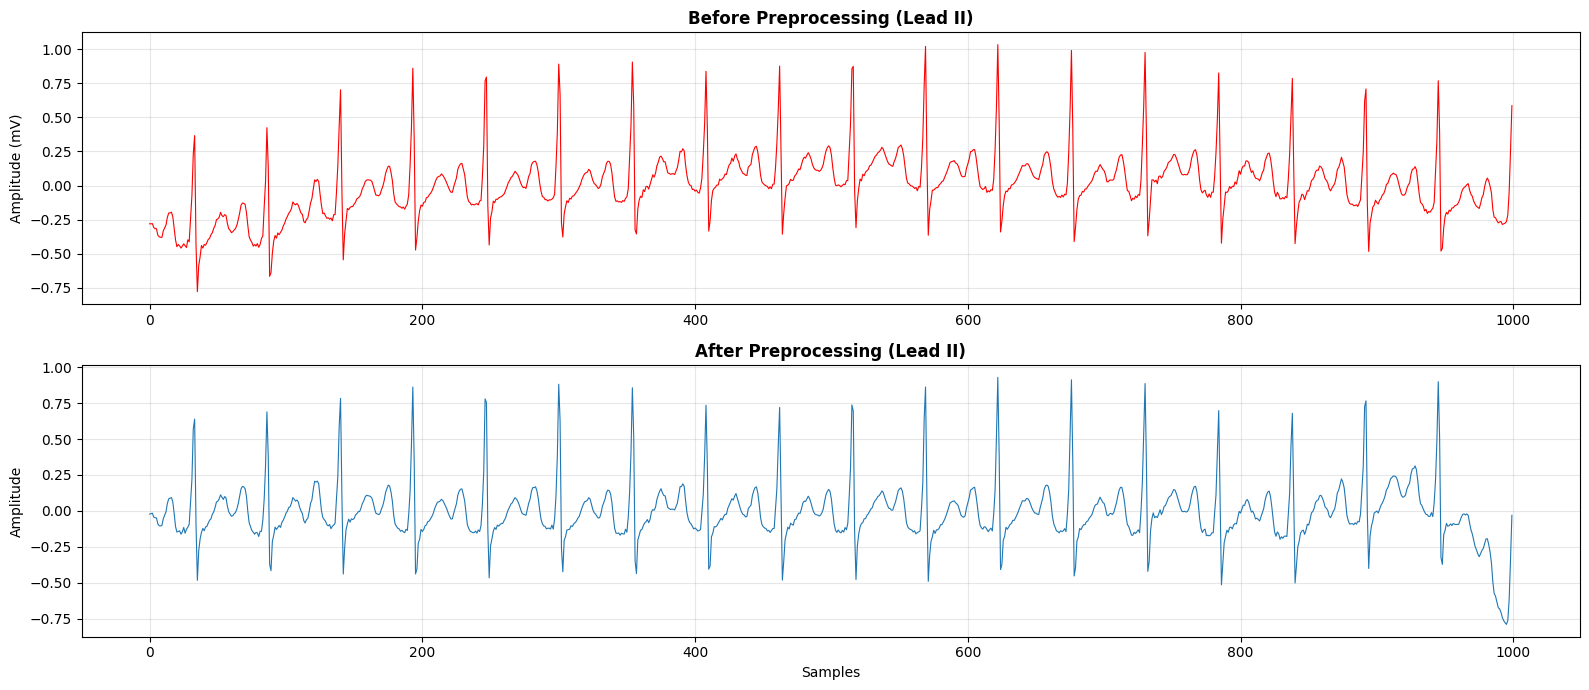

In [11]:
# ============================================================
# Visualize Before vs After Preprocessing
# ============================================================

import matplotlib.pyplot as plt

after_preprocess = X_filtered[sample_idx, :, lead_idx]
fig, axes = plt.subplots( 2, 1, figsize=(16,7) )


# Before
axes[0].plot( before_preprocess, linewidth=0.8, color='red' )
axes[0].set_title( "Before Preprocessing (Lead II)", fontsize=12, fontweight="bold" )
axes[0].set_ylabel("Amplitude (mV)")
axes[0].grid(True, alpha=0.3)

# After
axes[1].plot( after_preprocess, linewidth=0.8 )
axes[1].set_title( "After Preprocessing (Lead II)", fontsize=12, fontweight="bold" )
axes[1].set_xlabel("Samples")
axes[1].set_ylabel("Amplitude")
axes[1].grid(True, alpha=0.3)


plt.tight_layout()
plt.show()

In [12]:
from sklearn.preprocessing import MultiLabelBinarizer, StandardScaler
import numpy as np

def split_ptbxl(df, X):

    print("\nSplitting PTB-XL dataset...")

    train_mask = df["strat_fold"].isin(cfg.TRAIN_FOLDS)
    val_mask   = df["strat_fold"] == cfg.VAL_FOLD
    test_mask  = df["strat_fold"] == cfg.TEST_FOLD


    X_train = X[train_mask.values]
    X_val   = X[val_mask.values]
    X_test  = X[test_mask.values]


    y_train_labels = df.loc[train_mask, "labels"]
    y_val_labels   = df.loc[val_mask, "labels"]
    y_test_labels  = df.loc[test_mask, "labels"]


    patient_data_train = df.loc[train_mask, ['age', 'sex']].values.astype(np.float32)
    patient_data_val   = df.loc[val_mask, ['age', 'sex']].values.astype(np.float32)
    patient_data_test  = df.loc[test_mask, ['age', 'sex']].values.astype(np.float32)

    # Scale age using StandardScaler trained on training data
    scaler = StandardScaler()
    patient_data_train[:, 0] = scaler.fit_transform(patient_data_train[:, 0].reshape(-1, 1)).flatten()
    patient_data_val[:, 0]   = scaler.transform(patient_data_val[:, 0].reshape(-1, 1)).flatten()
    patient_data_test[:, 0]  = scaler.transform(patient_data_test[:, 0].reshape(-1, 1)).flatten()


    classes = sorted(
        list(set(
            label
            for group in df["labels"]
            for label in group
        ))
    )


    mlb = MultiLabelBinarizer(classes=classes)

    y_train = mlb.fit_transform(y_train_labels)
    y_val   = mlb.transform(y_val_labels)
    y_test  = mlb.transform(y_test_labels)


    print("Classes:", classes)
    print("Train:", X_train.shape, patient_data_train.shape, y_train.shape)
    print("Val  :", X_val.shape, patient_data_val.shape, y_val.shape)
    print("Test :", X_test.shape, patient_data_test.shape, y_test.shape)

    return ( X_train, X_val, X_test, patient_data_train, patient_data_val, patient_data_test, y_train, y_val, y_test, classes, mlb , {"train": train_mask, "val": val_mask, "test": test_mask})

( X_train, X_val, X_test, patient_data_train, patient_data_val, patient_data_test, y_train, y_val, y_test, classes, mlb, masks ) = split_ptbxl(df_meta, X_filtered)


Splitting PTB-XL dataset...
Classes: ['CD', 'HYP', 'MI', 'NORM', 'STTC']
Train: (17084, 1000, 12) (17084, 2) (17084, 5)
Val  : (2146, 1000, 12) (2146, 2) (2146, 5)
Test : (2158, 1000, 12) (2158, 2) (2158, 5)


In [ ]:

# dataset verification 

def verify_dataset(df, masks, y_train, y_val, y_test, classes):
    print("\n[6/8] Verifying dataset ...")
    for name, expected_folds, mask in [
        ("train", cfg.TRAIN_FOLDS, masks["train"]),
        ("val", [cfg.VAL_FOLD], masks["val"]),
        ("test", [cfg.TEST_FOLD], masks["test"]),
    ]:
        actual_folds = set(df.loc[mask, "strat_fold"].unique())
        assert actual_folds.issubset(set(expected_folds)), f"{name} split leaks folds: {actual_folds}"
    print("[PASS] Every split only contains its official strat_fold value(s).")

    dist = pd.DataFrame({
        "train": y_train.mean(axis=0) * 100,
        "val": y_val.mean(axis=0) * 100,
        "test": y_test.mean(axis=0) * 100,
    }, index=classes).round(2)
    print("\nPer-split positive rate (%) by class:")
    print(dist)
    return dist

verify_dataset(df_meta, masks, y_train, y_val, y_test, classes)



[6/8] Verifying dataset ...
[PASS] Every split only contains its official strat_fold value(s).

Per-split positive rate (%) by class:
      train    val   test
CD    22.87  23.07  22.98
HYP   12.40  12.49  12.14
MI    25.63  25.16  25.49
NORM  44.46  44.50  44.62
STTC  24.50  24.60  24.14


,train,val,test
CD,22.87,23.07,22.98
HYP,12.40,12.49,12.14
MI,25.63,25.16,25.49
NORM,44.46,44.50,44.62
STTC,24.50,24.60,24.14


In [14]:
def calculate_train_stats(X_train):

    print("\nCalculating train normalization parameters...")

    mean = X_train.mean(axis=(0,1))
    std  = X_train.std(axis=(0,1))
    std[std == 0] = 1e-8

    print("Mean shape:", mean.shape)
    print("STD shape :", std.shape)

    return mean, std



def normalize_data(X, mean, std):

    return ((X - mean) / std).astype(np.float32)


lead_mean, lead_std = calculate_train_stats(X_train)

X_train = normalize_data( X_train, lead_mean, lead_std )
X_val = normalize_data( X_val, lead_mean,  lead_std )
X_test = normalize_data( X_test, lead_mean, lead_std )

print("Normalization completed")

print( X_train.shape, X_val.shape, X_test.shape )


Calculating train normalization parameters...
Mean shape: (12,)
STD shape : (12,)
Normalization completed
(17084, 1000, 12) (2146, 1000, 12) (2158, 1000, 12)


In [15]:

# ============================================================
# 9. Augmentation
# ============================================================
def augment_ecg(x):
    # Gaussian noise
    if tf.random.uniform([]) < cfg.AUG_PROB:
        noise = tf.random.normal(tf.shape(x), mean=0, stddev=cfg.AUG_GAUSSIAN_NOISE_STD)
        x = x + noise

    # Amplitude scaling
    if tf.random.uniform([]) < cfg.AUG_PROB:
        lo, hi = cfg.AUG_AMPLITUDE_SCALE_RANGE
        x = x * tf.random.uniform([], lo, hi)

    # Time shift
    if tf.random.uniform([]) < cfg.AUG_PROB:
        shift = tf.random.uniform([], -cfg.AUG_TIME_SHIFT_MAX, cfg.AUG_TIME_SHIFT_MAX, dtype=tf.int32)
        x = tf.roll(x, shift=shift, axis=0)

    # Random lead dropout
    if tf.random.uniform([]) < cfg.AUG_LEAD_DROPOUT_PROB:
        num_leads = tf.shape(x)[-1]
        n_drop = tf.random.uniform([], 1, cfg.AUG_LEAD_DROPOUT_MAX_LEADS + 1, dtype=tf.int32)
        drop_idx = tf.random.shuffle(tf.range(num_leads))[:n_drop]
        mask = tf.reduce_max(tf.one_hot(drop_idx, num_leads), axis=0)
        x = x * (1.0 - mask)

    return x


def make_dataset(X_ecg, X_patient, y, batch_size, training=False):
    ds = tf.data.Dataset.from_tensor_slices(((X_ecg, X_patient), y))
    if training:
        ds = ds.shuffle(len(X_ecg), reshuffle_each_iteration=True)
        ds = ds.map(
            lambda inp, y: ((augment_ecg(inp[0]), inp[1]), y),
            num_parallel_calls=tf.data.AUTOTUNE,
        )
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds


train_ds = make_dataset(X_train, patient_data_train, y_train, cfg.BATCH_SIZE, training=True)
val_ds = make_dataset(X_val, patient_data_val, y_val, cfg.BATCH_SIZE, training=False)
test_ds = make_dataset(X_test, patient_data_test, y_test, cfg.BATCH_SIZE, training=False)

print("Dataset pipeline ready")

print(train_ds)
print(val_ds)
print(test_ds)

Dataset pipeline ready
<_PrefetchDataset element_spec=((TensorSpec(shape=(None, 1000, 12), dtype=tf.float32, name=None), TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)), TensorSpec(shape=(None, 5), dtype=tf.int64, name=None))>
<_PrefetchDataset element_spec=((TensorSpec(shape=(None, 1000, 12), dtype=tf.float32, name=None), TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)), TensorSpec(shape=(None, 5), dtype=tf.int64, name=None))>
<_PrefetchDataset element_spec=((TensorSpec(shape=(None, 1000, 12), dtype=tf.float32, name=None), TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)), TensorSpec(shape=(None, 5), dtype=tf.int64, name=None))>


In [16]:

# ============================================================
# Branch 1: Temporal branch
# ============================================================
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers

L2 = regularizers.l2(2e-4)


def se_block_1d(x, reduction=8, name=None):
    channels = x.shape[-1]
    se = layers.GlobalAveragePooling1D()(x)
    se = layers.Dense(max(channels // reduction, 4), activation="relu")(se)
    se = layers.Dense(channels, activation="sigmoid")(se)
    se = layers.Reshape((1, channels))(se)
    return layers.Multiply(name=name)([x, se])

def tcn_residual_block(x, filters, kernel_size, dilation_rate, dropout_rate=0.3):
    previous = x
    x = layers.Conv1D(filters, kernel_size, padding="causal", dilation_rate=dilation_rate,
                       kernel_regularizer=L2)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Dropout(dropout_rate)(x)

    x = layers.Conv1D(filters, kernel_size, padding="causal", dilation_rate=dilation_rate,
                       kernel_regularizer=L2)(x)
    x = layers.BatchNormalization()(x)

    if previous.shape[-1] != filters:
        previous = layers.Conv1D(filters, 1, padding="same")(previous)

    x = layers.Add()([previous, x])
    x = layers.Activation("relu")(x)
    return x

def build_tcn(x, filters=64, kernel_size=3, num_blocks=4, dropout_rate=0.3):
    for i in range(num_blocks):
        x = tcn_residual_block(x, filters, kernel_size, dilation_rate=2 ** i, dropout_rate=dropout_rate)
    return x

def temporal_branch(signal_input):
    x = layers.Conv1D(48, kernel_size=7, padding="same", kernel_regularizer=L2)(signal_input)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    x = layers.Conv1D(96, kernel_size=5, padding="same", kernel_regularizer=L2)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling1D(2)(x)

    x = layers.Conv1D(128, kernel_size=5, padding="same", kernel_regularizer=L2)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling1D(2)(x)

    x = build_tcn(x, filters=64, num_blocks=4, dropout_rate=0.3)
    x = se_block_1d(x, reduction=8, name="se_attention")
    return layers.GlobalAveragePooling1D()(x)


In [17]:
# ============================================================
# Branch 2: Spectral branch
# ============================================================
class STFTLayer(layers.Layer):
    def __init__(self, frame_length=256, frame_step= 64, fft_length=256, **kwargs):
        super().__init__(**kwargs)
        self.frame_length = frame_length
        self.frame_step = frame_step
        self.fft_length = fft_length

    def call(self, x):
        x = tf.transpose(x, [0, 2, 1])
        spec = tf.signal.stft(x, frame_length=self.frame_length,
                               frame_step=self.frame_step, fft_length=self.fft_length)
        mag = tf.math.log1p(tf.abs(spec))
        return tf.transpose(mag, [0, 3, 2, 1])

    def compute_output_shape(self, input_shape):
        batch, time, leads = input_shape
        frames = 1 + (time - self.frame_length) // self.frame_step
        freq_bins = self.fft_length // 2 + 1
        return (batch, freq_bins, frames, leads)

def transformer_encoder_block(x, num_heads=4, key_dim=32, ff_dim=128, dropout_rate=0.3):
    attn_out = layers.MultiHeadAttention(num_heads=num_heads, key_dim=key_dim, dropout=dropout_rate)(x, x)
    x = layers.Add()([x, attn_out])
    x = layers.LayerNormalization()(x)
    ff = layers.Dense(ff_dim, activation="gelu", kernel_regularizer=L2)(x)
    ff = layers.Dense(x.shape[-1])(ff)
    ff = layers.Dropout(dropout_rate)(ff)
    x = layers.Add()([x, ff])
    x = layers.LayerNormalization()(x)
    return x

class AttentionPooling1D(layers.Layer):
    def __init__(self, units=64, **kwargs):
        super().__init__(**kwargs)
        self.units = units

    def build(self, input_shape):
        self.score_dense1 = layers.Dense(self.units, activation="tanh")
        self.score_dense2 = layers.Dense(1)
        super().build(input_shape)

    def call(self, x):
        scores = self.score_dense2(self.score_dense1(x))
        weights = tf.nn.softmax(scores, axis=1)
        return tf.reduce_sum(x * weights, axis=1)

    def compute_output_shape(self, input_shape):
        return (input_shape[0], input_shape[-1])


def spectral_branch(signal_input):
    x = STFTLayer()(signal_input)

    x = layers.Conv2D(24, (3, 3), padding="same", kernel_regularizer=L2)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    x = layers.MaxPooling2D((2, 1))(x)

    x = layers.Conv2D(48, (3, 3), padding="same", kernel_regularizer=L2)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    x = layers.MaxPooling2D((2, 1))(x)

    shape = x.shape
    x = layers.Reshape((shape[1] * shape[2], shape[3]))(x)
    x = transformer_encoder_block(x, num_heads=4, key_dim=32, ff_dim=128)
    return AttentionPooling1D()(x)


In [18]:
# ============================================================
# Branch 3: Patient metadata
# ============================================================
def patient_branch(patient_input):
    p = layers.Dense(32, activation="relu")(patient_input)
    p = layers.BatchNormalization()(p)
    p = layers.Dropout(0.2)(p)
    p = layers.Dense(16, activation="relu")(p)
    p = layers.BatchNormalization()(p)
    return p


In [19]:

# ============================================================
# Fusion + classifier
# ============================================================
def gated_multimodal_fusion(temporal_vec, spectral_vec, dim=96):

    t = layers.Dense(dim, activation="tanh")(temporal_vec)
    s = layers.Dense(dim, activation="tanh")(spectral_vec)

    gate_input = layers.Concatenate()([temporal_vec, spectral_vec])
    z = layers.Dense(dim, activation="sigmoid", name="fusion_gate")(gate_input)

    fused = layers.Add(name="fused_features")([
        layers.Multiply()([z, t]),

        layers.Multiply()([layers.Lambda(lambda x: 1 - x)(z), s])
    ])
    return fused

def classifier(fusion, num_classes):
    x = layers.Dense(256, kernel_regularizer=L2)(fusion)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Dropout(0.4)(x)

    x = layers.Dense(128, kernel_regularizer=L2)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Dropout(0.3)(x)

    return layers.Dense(num_classes, activation="sigmoid", name="diagnosis_output")(x)

def build_model(signal_len, num_leads, num_classes):
    input_ecg = layers.Input(shape=(signal_len, num_leads), name="ecg_signal")
    patient_input = layers.Input(shape=(2,), name="patient_input")

    temporal = temporal_branch(input_ecg)
    spectral = spectral_branch(input_ecg)
    patient_features = patient_branch(patient_input)

    fusion = gated_multimodal_fusion(temporal, spectral)
    fusion = layers.Concatenate(name="fusion_with_patient")([fusion, patient_features])

    output = classifier(fusion, num_classes)
    return keras.Model(inputs=[input_ecg, patient_input], outputs=output, name="ECG_DualBranch_v2")


In [20]:
model = build_model(signal_len=cfg.SIGNAL_LENGTH, num_leads=cfg.NUM_LEADS, num_classes=len(classes))

model.compile(
    optimizer=tf.optimizers.AdamW(learning_rate=1e-3, weight_decay=1e-4),
    loss=  "binary_crossentropy",
    metrics=[
        keras.metrics.AUC(multi_label=True, name="macro_auc"),
        keras.metrics.BinaryAccuracy(name="binary_accuracy"),
    ]
)
model.summary()

Model: "ECG_DualBranch_v2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ ecg_signal          │ (None, 1000, 12)  │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 1000, 48)  │      4,080 │ ecg_signal[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 1000, 48)  │        192 │ conv1d[0][0]      │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 1000, 48)  │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 1000, 96)  │     23,136 │ activation[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 1000, 96)  │        384 │ conv1d_1[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 1000, 96)  │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d       │ (None, 500, 96)   │          0 │ activation_1[0][… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 500, 128)  │     61,568 │ max_pooling1d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 500, 128)  │        512 │ conv1d_2[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 500, 128)  │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_1     │ (None, 250, 128)  │          0 │ activation_2[0][… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 250, 64)   │     24,640 │ max_pooling1d_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 250, 64)   │        256 │ conv1d_3[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 250, 64)   │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 250, 64)   │          0 │ activation_3[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_4 (Conv1D)   │ (None, 250, 64)   │     12,352 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_5 (Conv1D)   │ (None, 250, 64)   │      8,256 │ max_pooling1d_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 250, 64)   │        256 │ conv1d_4[0][0]    │
│ (BatchNormalizatio… │                   │            │                 

 Total params: 349,973 (1.34 MB)

 Trainable params: 347,397 (1.33 MB)

 Non-trainable params: 2,576 (10.06 KB)

In [21]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_macro_auc", mode="max",
                                   patience=10, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_macro_auc", mode="max",
                                       factor=0.5, patience=4, min_lr=1e-6),
]

history = model.fit(train_ds, validation_data=val_ds, epochs=60, callbacks=callbacks, verbose=1)


Epoch 1/60
534/534 ━━━━━━━━━━━━━━━━━━━━ 73s 87ms/step - binary_accuracy: 0.8283 - loss: 0.5576 - macro_auc: 0.8453 - val_binary_accuracy: 0.8507 - val_loss: 0.4953 - val_macro_auc: 0.8885 - learning_rate: 0.0010
Epoch 2/60
534/534 ━━━━━━━━━━━━━━━━━━━━ 45s 84ms/step - binary_accuracy: 0.8668 - loss: 0.4234 - macro_auc: 0.8934 - val_binary_accuracy: 0.8286 - val_loss: 0.4784 - val_macro_auc: 0.8932 - learning_rate: 0.0010
Epoch 3/60
534/534 ━━━━━━━━━━━━━━━━━━━━ 46s 85ms/step - binary_accuracy: 0.8729 - loss: 0.3778 - macro_auc: 0.9049 - val_binary_accuracy: 0.8607 - val_loss: 0.3884 - val_macro_auc: 0.9065 - learning_rate: 0.0010
Epoch 4/60
534/534 ━━━━━━━━━━━━━━━━━━━━ 45s 84ms/step - binary_accuracy: 0.8777 - loss: 0.3520 - macro_auc: 0.9106 - val_binary_accuracy: 0.8599 - val_loss: 0.3790 - val_macro_auc: 0.9132 - learning_rate: 0.0010
Epoch 5/60
534/534 ━━━━━━━━━━━━━━━━━━━━ 45s 84ms/step - binary_accuracy: 0.8802 - loss: 0.3377 - macro_auc: 0.9131 - val_binary_accuracy: 0.8646 - val_l

In [22]:
from sklearn.metrics import f1_score, roc_auc_score

val_probs = model.predict(val_ds)
val_preds = (val_probs > 0.5).astype(int)

val_binary_accuracy = np.mean(y_val == val_preds)
val_macro_auc = roc_auc_score(y_val, val_probs, average="macro")

print(f"Validation Macro AUC       : {val_macro_auc:.4f}")
print(f"Validation Binary Accuracy: {val_binary_accuracy:.4f}")
print("Validation Macro F1:", f1_score(y_val, val_preds, average="macro", zero_division=0))
print("Per-class F1:", f1_score(y_val, val_preds, average=None, zero_division=0))

68/68 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step
Validation Macro AUC       : 0.9352
Validation Binary Accuracy: 0.8908
Validation Macro F1: 0.7428369879332939
Per-class F1: [0.78506559 0.56880734 0.75568744 0.86873747 0.7358871 ]


In [23]:
import numpy as np
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    f1_score, precision_score, recall_score,
    accuracy_score, hamming_loss, classification_report
)

def evaluate_model(model, dataset, y_true, class_names, thresholds=None):

    y_prob = model.predict(dataset)
    num_classes = y_true.shape[1]

    if thresholds is None:
        thresholds = np.full(num_classes, 0.5)
    y_pred = (y_prob > thresholds).astype(int)

    results = {}

    # ---- Threshold-independent metrics ----
    results["macro_auc"] = roc_auc_score(y_true, y_prob, average="macro")

    per_class_auc = roc_auc_score(y_true, y_prob, average=None)
    results["per_class_auc"] = dict(zip(class_names, per_class_auc.tolist()))

    # ---- Threshold-dependent metrics ----
    results["macro_f1"] = f1_score(y_true, y_pred, average="macro", zero_division=0)
    results["macro_precision"] = precision_score(y_true, y_pred, average="macro", zero_division=0)
    results["macro_recall"] = recall_score(y_true, y_pred, average="macro", zero_division=0)

    per_class_f1 = f1_score(y_true, y_pred, average=None, zero_division=0)
    results["per_class_f1"] = dict(zip(class_names, per_class_f1.tolist()))

    results["binary_accuracy"] = np.mean(y_true == y_pred)
    results["hamming_loss"] = hamming_loss(y_true, y_pred)

    return results, y_prob, y_pred


def print_evaluation(results, class_names):
    print("=" * 60)
    print("Scores")
    print("=" * 60)

    print(f"Test Macro AUC       : {results['macro_auc']:.4f}")
    print(f"Test Macro F1        : {results['macro_f1']:.4f}")
    print(f"Test binary accuracy   : {results['binary_accuracy']:.4f}")
    print(f"Test Hamming loss      : {results['hamming_loss']:.4f}")

    print("\nPer-class AUC-ROC:")
    for c, v in results["per_class_auc"].items():
        print(f"  {c:8s}: {v:.4f}")

    print("\nPer-class F1:")
    for c, v in results["per_class_f1"].items():
        print(f"  {c:8s}: {v:.4f}")



# Evaluate on TEST set
results, y_prob, y_pred = evaluate_model(model, test_ds, y_test, classes)  # thresholds=None -> 0.5
print_evaluation(results, classes)

68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step
Scores
Test Macro AUC       : 0.9342
Test Macro F1        : 0.7548
Test binary accuracy   : 0.8964
Test Hamming loss      : 0.1036

Per-class AUC-ROC:
  CD      : 0.9333
  HYP     : 0.9103
  MI      : 0.9353
  NORM    : 0.9529
  STTC    : 0.9391

Per-class F1:
  CD      : 0.7888
  HYP     : 0.5917
  MI      : 0.7451
  NORM    : 0.8769
  STTC    : 0.7716


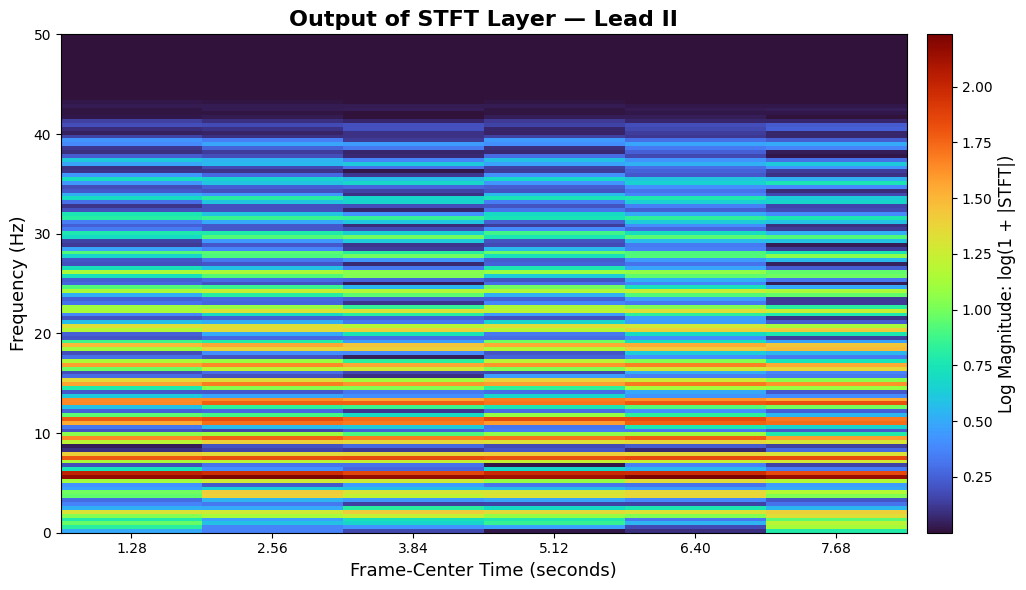

In [ ]:
# ============================================================
# Fig. 3 — Output of STFT Layer (Lead II)
# ============================================================
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# ---- settings ------------------------------------------------
sample_idx = 500        
lead_idx   = 1          # Lead II
fs         = cfg.SAMPLING_RATE      # 100 Hz
frame_len  = 256
frame_step = 128
fft_len    = 256

sig = np.asarray(X_filtered[sample_idx], dtype=np.float32)          # (1000, 12)
stft_layer = STFTLayer(frame_length=frame_len, frame_step=frame_step, fft_length=fft_len)
out = stft_layer(sig[None, ...]).numpy()                            # (1, 129, frames, 12)
mag = out[0, :, :, lead_idx]                                        # (129, frames)  = log(1+|STFT|)

n_frames = mag.shape[1]
centers  = (np.arange(n_frames) * frame_step + frame_len / 2) / fs  
half     = frame_step / fs / 2                                      

# ---- plot ----------------------------------------------------
fig, ax = plt.subplots(figsize=(11, 6))
im = ax.imshow(
    mag,
    origin="lower",
    aspect="auto",
    cmap="turbo",
    interpolation="nearest",
    extent=[centers[0] - half, centers[-1] + half, 0, fs / 2],
)
ax.set_title("Output of STFT Layer — Lead II", fontsize=16, fontweight="bold")
ax.set_xlabel("Frame-Center Time (seconds)", fontsize=13)
ax.set_ylabel("Frequency (Hz)", fontsize=13)
ax.set_xticks(centers)
ax.set_xticklabels([f"{c:.2f}" for c in centers])
ax.set_yticks(np.arange(0, 51, 10))

cbar = fig.colorbar(im, ax=ax, pad=0.02)
cbar.set_label("Log Magnitude: log(1 + |STFT|)", fontsize=12)

plt.tight_layout()
plt.savefig("stft_layer_output_lead2.png", dpi=300, bbox_inches="tight")
plt.show()

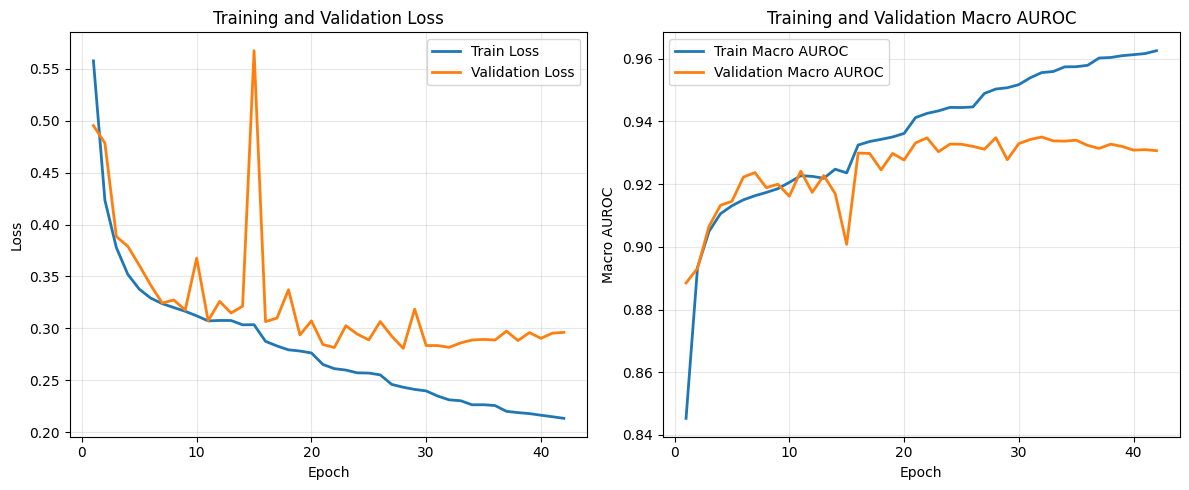

Figure saved to: figures/training_curves.png


In [25]:
import os
import numpy as np
import matplotlib.pyplot as plt


def plot_training_curves(history, save_dir="figures"):
    os.makedirs(save_dir, exist_ok=True)

    epochs = np.arange(1, len(history.history['loss']) + 1)

    metric_pairs = [
        ("loss", "val_loss", "Loss", "Training and Validation Loss"),
        ("macro_auc", "val_macro_auc", "Macro AUROC", "Training and Validation Macro AUROC"),
    ]

    fig, axes = plt.subplots(1, len(metric_pairs), figsize=(12, 5))

    for ax, (train_key, val_key, ylabel, title) in zip(axes, metric_pairs):
        ax.plot(epochs, history.history[train_key], label=f"Train {ylabel}", linewidth=2)
        ax.plot(epochs, history.history[val_key], label=f"Validation {ylabel}", linewidth=2)
        ax.set_title(title)
        ax.set_xlabel("Epoch")
        ax.set_ylabel(ylabel)
        ax.legend()
        ax.grid(alpha=0.3)

    plt.tight_layout()

    save_path = os.path.join(save_dir, "training_curves.png")
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()

    print(f"Figure saved to: {save_path}")


plot_training_curves(history)

68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step


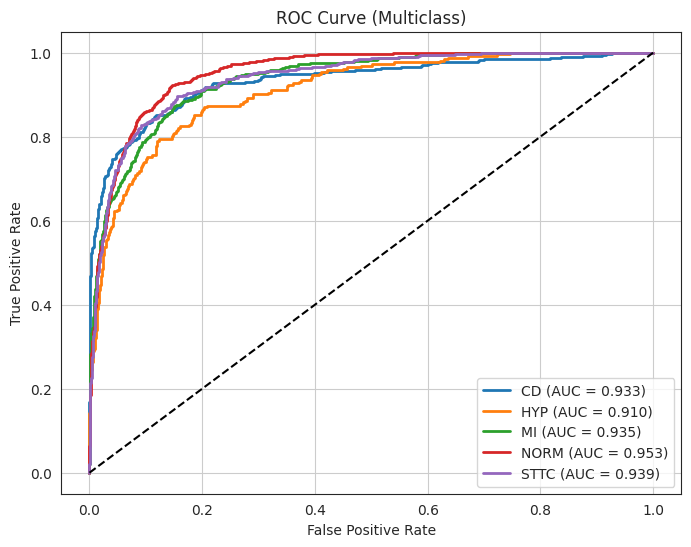

Macro AUC: 0.9342


In [33]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
import numpy as np

y_pred = model.predict(test_ds)
y_true = y_test

class_names = classes

plt.figure(figsize=(8,6))

auc_scores = []

for i in range(len(class_names)):
    fpr, tpr, _ = roc_curve(y_true[:, i], y_pred[:, i])
    roc_auc = auc(fpr, tpr)

    auc_scores.append(roc_auc)

    plt.plot(fpr, tpr,
             linewidth=2,
             label=f"{class_names[i]} (AUC = {roc_auc:.3f})")

plt.plot([0,1],[0,1],'k--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve (Multiclass)")
plt.legend(loc="lower right")
plt.grid(True)

plt.show()

print(f"Macro AUC: {np.mean(auc_scores):.4f}")

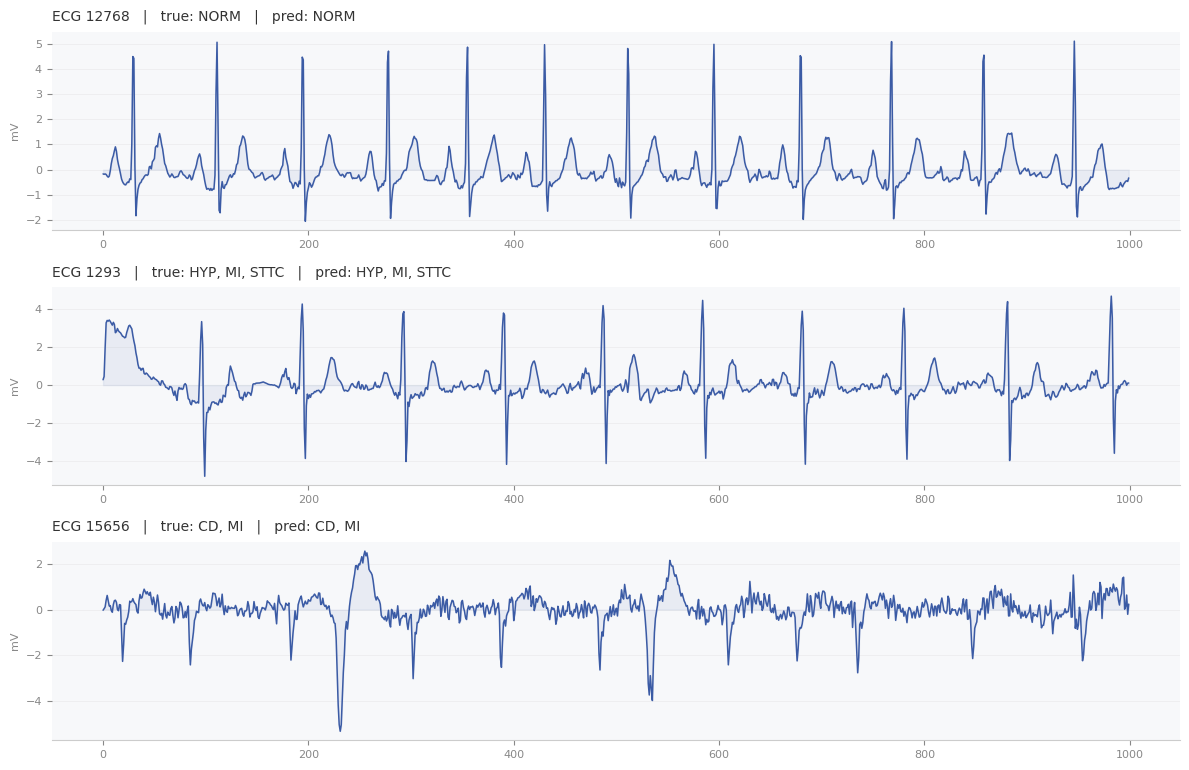

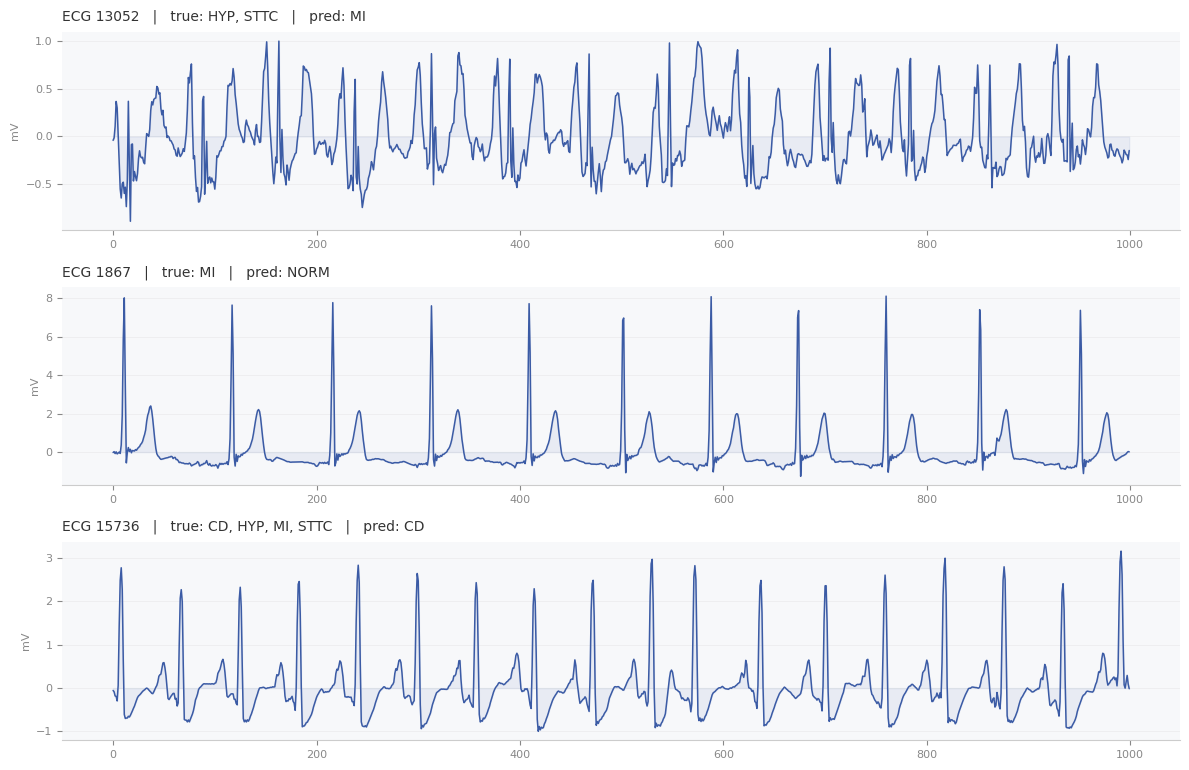

In [27]:
def plot_prediction_examples(X_test, y_true, y_prob, ecg_ids, class_names,
                              lead_idx=1, n_examples=3, save_dir="figures",
                              random_seed=42):
    os.makedirs(save_dir, exist_ok=True)

    y_pred = (y_prob >= 0.5).astype(int)
    correct_mask = (y_pred == y_true).all(axis=1)

    signal_color = "#3B5BA5"
    bg_color = "#F7F8FA"

    for name, mask in [("correct", correct_mask), ("incorrect", ~correct_mask)]:
        idx = np.where(mask)[0]
        if len(idx) == 0:
            continue

        chosen = np.random.default_rng(random_seed).choice(idx, size=min(n_examples, len(idx)), replace=False)

        fig, axes = plt.subplots(
            len(chosen), 1,
            figsize=(12, 2.6 * len(chosen)),
            squeeze=False,
            facecolor="white"
        )

        for ax, i in zip(axes[:, 0], chosen):
            ecg_id = ecg_ids[i]
            signal = X_test[i][:, lead_idx]

            true_labels = [class_names[j] for j, v in enumerate(y_true[i]) if v > 0.5] or ["(none)"]
            pred_labels = [class_names[j] for j, v in enumerate(y_prob[i]) if v >= 0.5] or ["(none)"]

            ax.set_facecolor(bg_color)
            ax.plot(signal, linewidth=1.1, color=signal_color, solid_capstyle="round")
            ax.fill_between(np.arange(len(signal)), signal, color=signal_color, alpha=0.08)

            ax.set_title(
                f"ECG {ecg_id}   |   true: {', '.join(true_labels)}   |   pred: {', '.join(pred_labels)}",
                fontsize=10, loc="left", fontweight="medium", color="#333333", pad=8
            )

            for spine in ("top", "right", "left"):
                ax.spines[spine].set_visible(False)
            ax.spines["bottom"].set_color("#CCCCCC")
            ax.tick_params(axis="both", labelsize=8, colors="#888888")
            ax.set_ylabel("mV", fontsize=8, color="#888888")
            ax.grid(axis="y", alpha=0.15, linewidth=0.6)

        plt.tight_layout()
        plt.savefig(os.path.join(save_dir, f"17_examples_{name}.png"), dpi=200, bbox_inches="tight")
        plt.show()


test_ecg_ids = df_meta.loc[masks["test"]].index.to_numpy()
plot_prediction_examples(X_test, y_test, y_pred, test_ecg_ids, class_names)

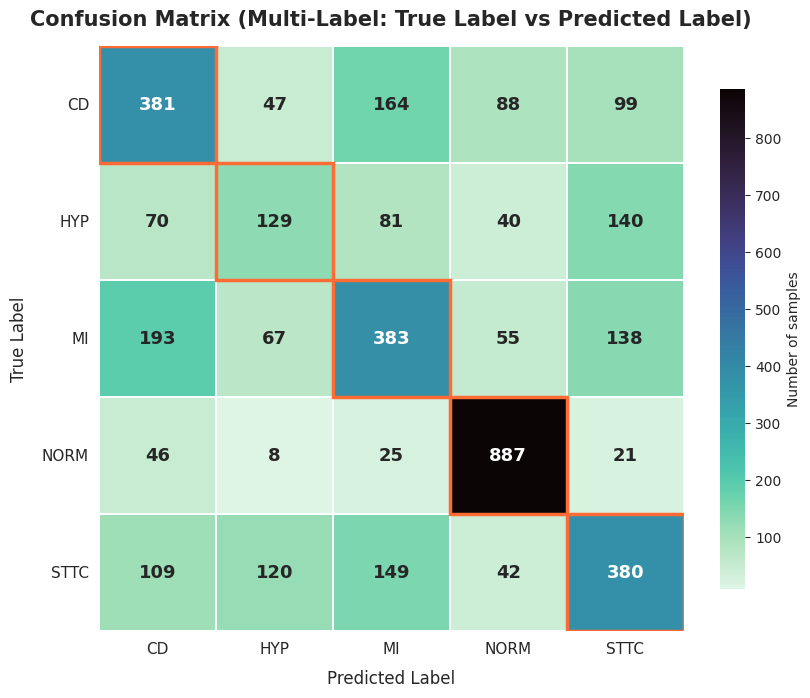

Confusion matrix (true-label -> predicted-label counts):
[[381  47 164  88  99]
 [ 70 129  81  40 140]
 [193  67 383  55 138]
 [ 46   8  25 887  21]
 [109 120 149  42 380]]


In [28]:
# ============================================================
# 5x5 Confusion Matrix — Multi-Label Version
# ============================================================
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import os

y_pred_binary = (y_pred >= 0.5).astype(int)

n_classes = len(class_names)
cm = np.zeros((n_classes, n_classes), dtype=int)

for true_row, pred_row in zip(y_true, y_pred_binary):
    true_idx = np.where(true_row == 1)[0]
    pred_idx = np.where(pred_row == 1)[0]
    for i in true_idx:
        for j in pred_idx:
            cm[i, j] += 1

sns.set_style("white")
fig, ax = plt.subplots(figsize=(8.5, 7))

cmap = sns.color_palette("mako_r", as_cmap=True)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap=cmap,
    xticklabels=class_names,
    yticklabels=class_names,
    cbar_kws={"label": "Number of samples", "shrink": 0.85},
    square=True,
    linewidths=1.2,
    linecolor="white",
    annot_kws={"size": 13, "weight": "bold"},
    ax=ax
)

for i in range(n_classes):
    ax.add_patch(plt.Rectangle((i, i), 1, 1, fill=False, edgecolor="#FF6B35", lw=2.5))

ax.set_title("Confusion Matrix (Multi-Label: True Label vs Predicted Label)", fontsize=15, fontweight="bold", pad=15)
ax.set_xlabel("Predicted Label", fontsize=12, fontweight="medium", labelpad=10)
ax.set_ylabel("True Label", fontsize=12, fontweight="medium", labelpad=10)
ax.tick_params(labelsize=11)
plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.tight_layout()

save_dir = "figures"
os.makedirs(save_dir, exist_ok=True)
plt.savefig(os.path.join(save_dir, "confusion_matrix_5x5.png"), dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

print("Confusion matrix (true-label -> predicted-label counts):")
print(cm)

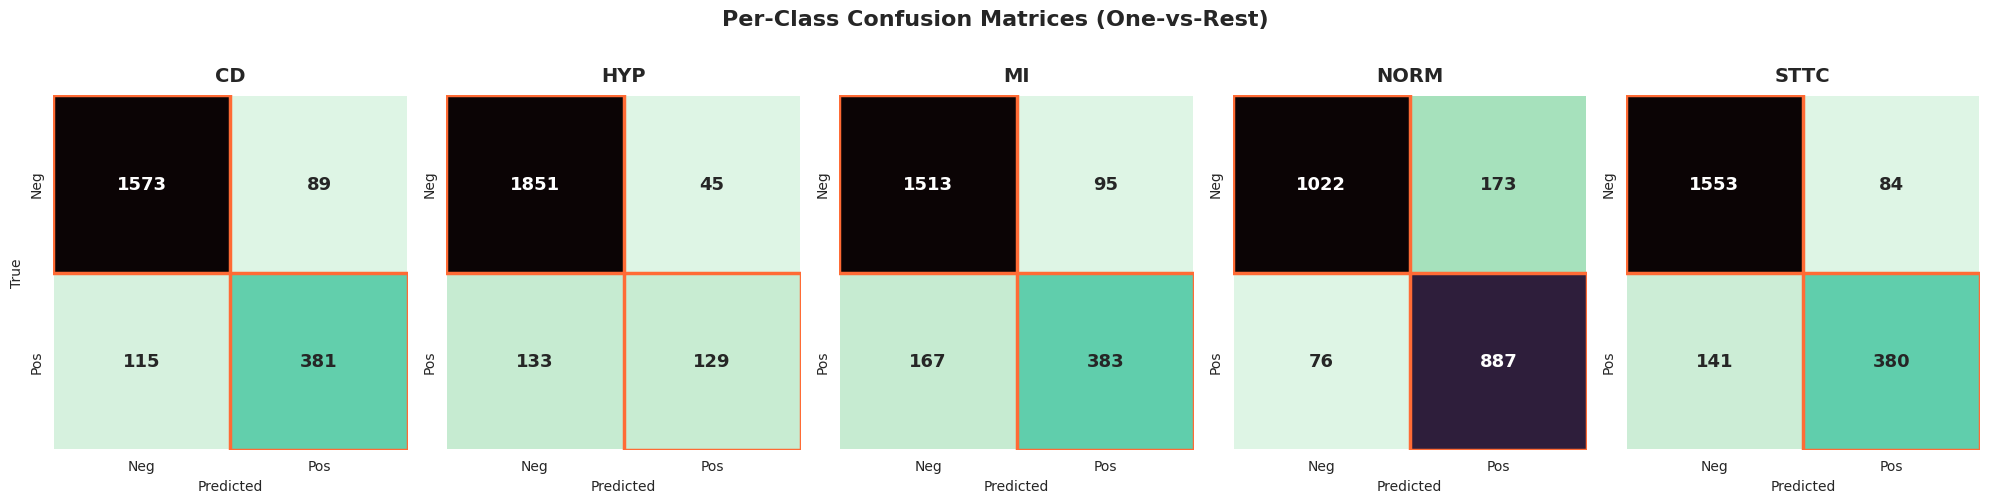

CD: TN=1573, FP=89, FN=115, TP=381
HYP: TN=1851, FP=45, FN=133, TP=129
MI: TN=1513, FP=95, FN=167, TP=383
NORM: TN=1022, FP=173, FN=76, TP=887
STTC: TN=1553, FP=84, FN=141, TP=380


In [ ]:
# ============================================================
# Per-Class Confusion Matrices (5 separate 2x2 matrices)
# ============================================================
from sklearn.metrics import multilabel_confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import os


y_pred_binary = (y_pred >= 0.5).astype(int)

# Returns array of shape (n_classes, 2, 2)
# Each 2x2 matrix: [[TN, FP], [FN, TP]]
mcm = multilabel_confusion_matrix(y_true, y_pred_binary)

sns.set_style("white")
cmap = sns.color_palette("mako_r", as_cmap=True)

fig, axes = plt.subplots(1, len(class_names), figsize=(4 * len(class_names), 4.5))

for i, (ax, cls) in enumerate(zip(axes, class_names)):
    cm = mcm[i]

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap=cmap,
        xticklabels=["Neg", "Pos"],
        yticklabels=["Neg", "Pos"],
        cbar=False,
        square=True,
        linewidths=1.2,
        linecolor="white",
        annot_kws={"size": 13, "weight": "bold"},
        ax=ax
    )

    ax.add_patch(plt.Rectangle((0, 0), 1, 1, fill=False, edgecolor="#FF6B35", lw=2.5))
    ax.add_patch(plt.Rectangle((1, 1), 1, 1, fill=False, edgecolor="#FF6B35", lw=2.5))

    ax.set_title(cls, fontsize=14, fontweight="bold", pad=10)
    ax.set_xlabel("Predicted", fontsize=10)
    ax.set_ylabel("True" if i == 0 else "", fontsize=10)
    ax.tick_params(labelsize=10)

fig.suptitle("Per-Class Confusion Matrices (One-vs-Rest)", fontsize=16, fontweight="bold", y=1.05)
plt.tight_layout()

save_dir = "figures"
os.makedirs(save_dir, exist_ok=True)
plt.savefig(os.path.join(save_dir, "confusion_matrix_per_class.png"), dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

for cls, cm in zip(class_names, mcm):
    tn, fp, fn, tp = cm.ravel()
    print(f"{cls}: TN={tn}, FP={fp}, FN={fn}, TP={tp}")

In [ ]:

def predict_by_ecg_id(ecg_id, threshold=0.5, verbose=True):
    split_lookup = [
        ("train", X_train, patient_data_train, y_train, masks["train"]),
        ("val",   X_val,   patient_data_val,   y_val,   masks["val"]),
        ("test",  X_test,  patient_data_test,  y_test,  masks["test"]),
    ]

    idx = None
    for split_name, X_split, patient_split, y_split, mask in split_lookup:
        split_ecg_ids = df_meta.loc[mask, "ecg_id"].to_numpy()
        matches = np.where(split_ecg_ids == ecg_id)[0]
        if len(matches) > 0:
            idx = matches[0]
            break

    if idx is None:
        raise ValueError(f"ecg_id {ecg_id} not found in df_meta / any split.")

    signal  = X_split[idx:idx + 1]
    patient = patient_split[idx:idx + 1]
    true_vec = y_split[idx]

    pred_prob = model.predict([signal, patient], verbose=0)[0]
    pred_vec  = (pred_prob >= threshold).astype(int)

    true_labels = [classes[i] for i, v in enumerate(true_vec) if v == 1] or ["(none)"]
    pred_labels = [classes[i] for i, v in enumerate(pred_vec) if v == 1] or ["(none)"]

    if verbose:
        print(f"ecg_id: {ecg_id}  (found in '{split_name}' split, row {idx})")
        print(f"True label(s):      {true_labels}")
        print(f"Predicted label(s): {pred_labels}  (threshold={threshold})")
        print("\nPer-class predicted probability:")
        for cls, p in zip(classes, pred_prob):
            flag = " <-- true" if cls in true_labels else ""
            print(f"  {cls:6s}: {p:.4f}{flag}")

    return {
        "ecg_id": ecg_id,
        "split": split_name,
        "row_index": idx,
        "true_labels": true_labels,
        "pred_labels": pred_labels,
        "pred_prob": dict(zip(classes, pred_prob.tolist())),
    }


# Example usage:
result = predict_by_ecg_id(15871)

ecg_id: 15871  (found in 'test' split, row 1655)
True label(s):      ['HYP', 'MI', 'STTC']
Predicted label(s): ['HYP', 'MI', 'STTC']  (threshold=0.5)

Per-class predicted probability:
  CD    : 0.2720
  HYP   : 0.6906 <-- true
  MI    : 0.9569 <-- true
  NORM  : 0.0002
  STTC  : 0.6799 <-- true


ECG 15871 | split=test | idx=1655 | signal=(1, 1000, 12) | patient=(1, 2)
True: ['HYP', 'MI', 'STTC'] | Pred: ['HYP', 'MI', 'STTC'] | threshold=0.5
CD        : 0.2720
HYP       : 0.6906  <-- TRUE  <-- PRED
MI        : 0.9569  <-- TRUE  <-- PRED
NORM      : 0.0002
STTC      : 0.6799  <-- TRUE  <-- PRED


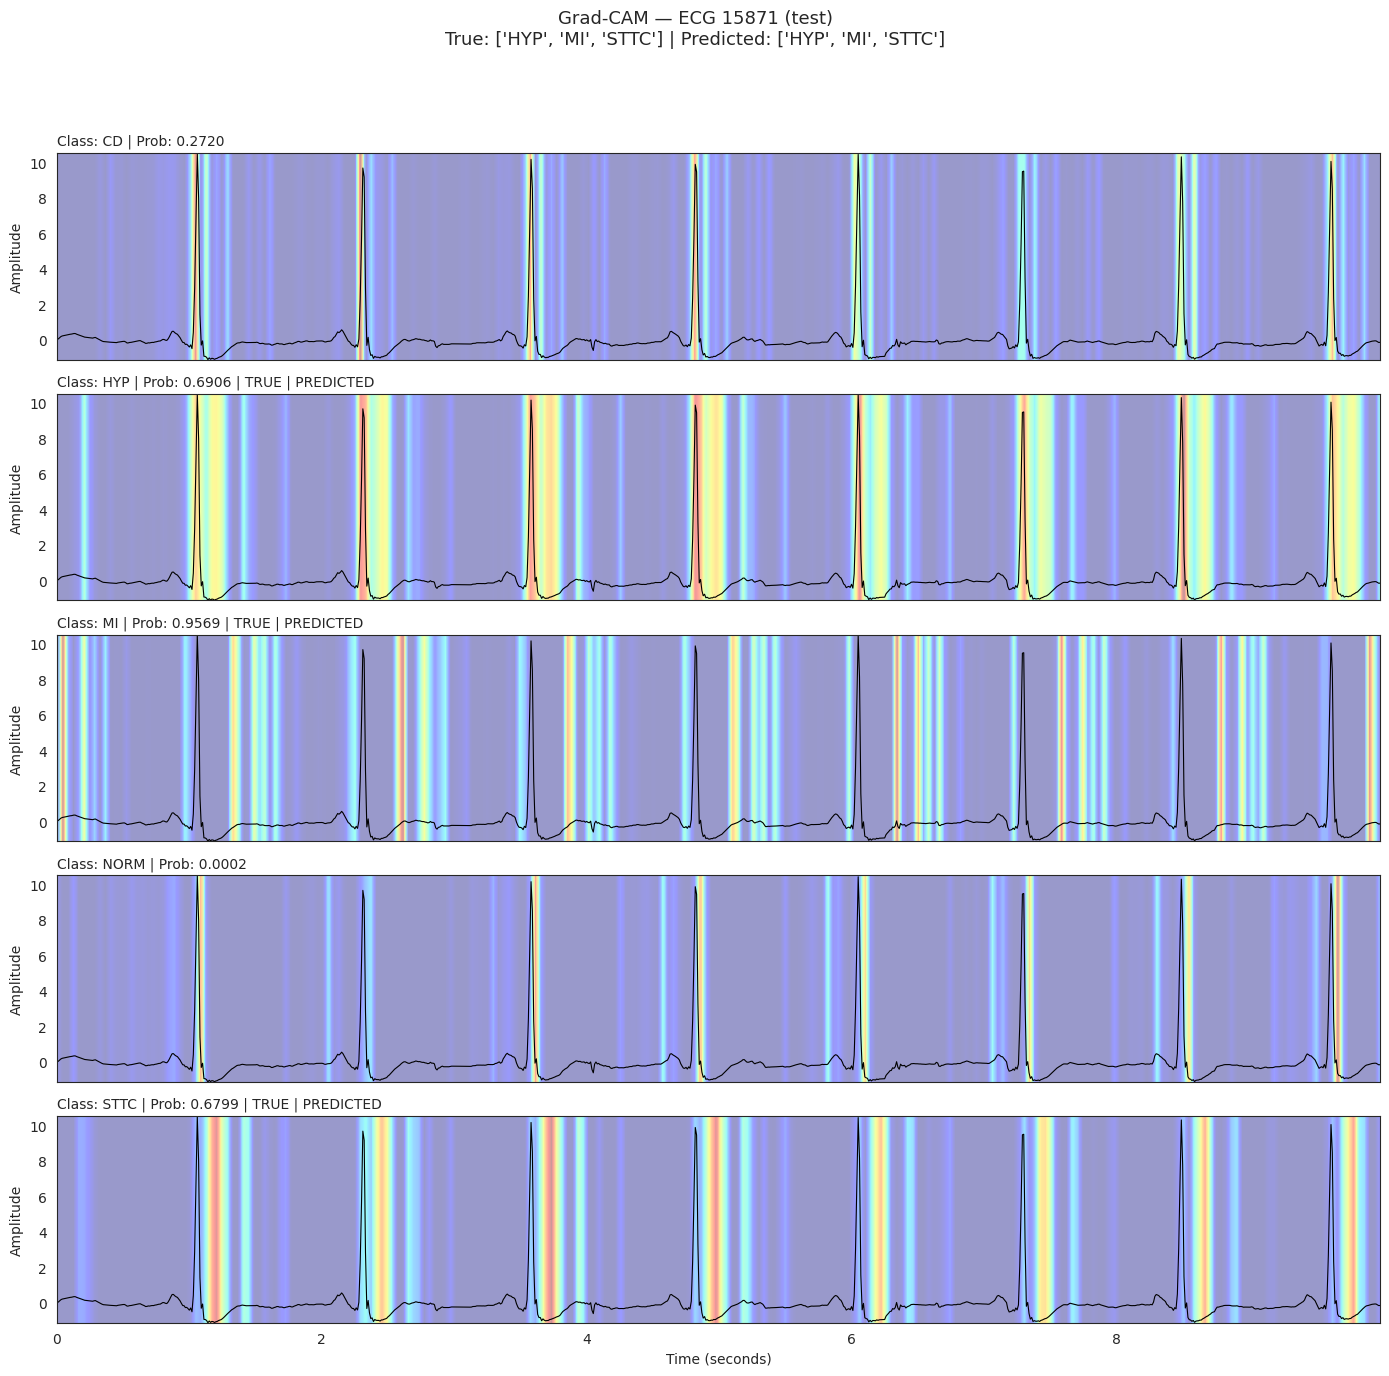

Saved: figures/18_gradcam_ecg_15871.png
Feature map shape (se_attention): (250, 64)


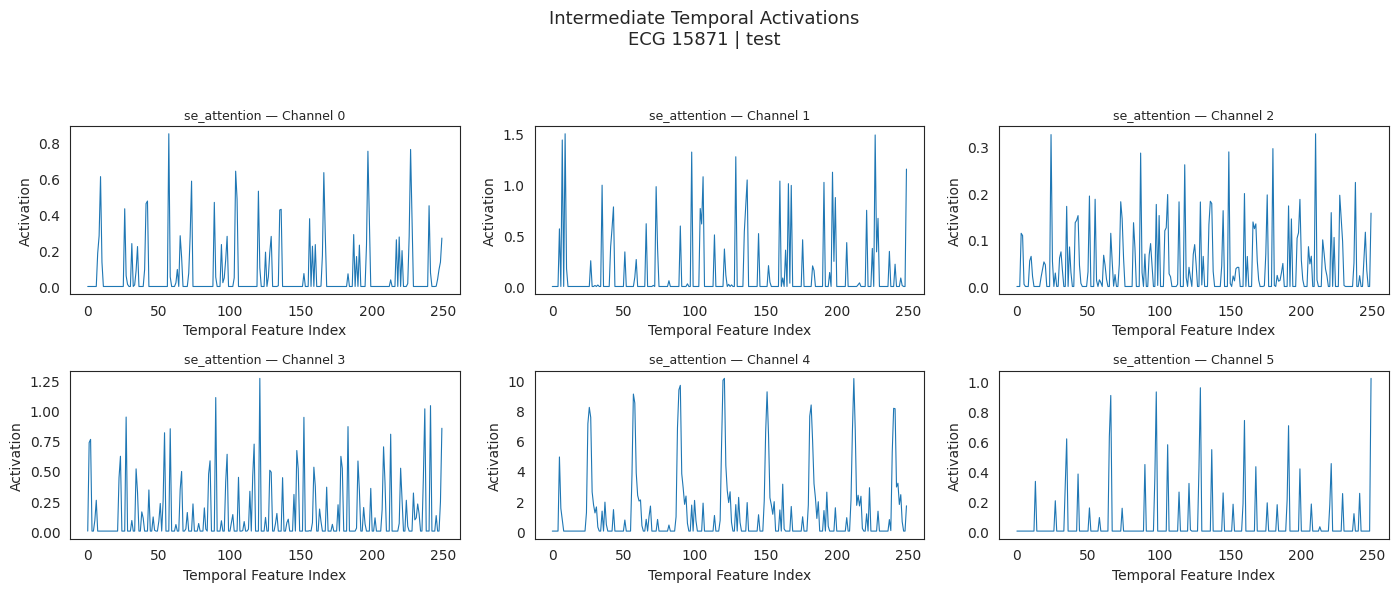

Saved: figures/18_feature_maps_ecg_15871.png


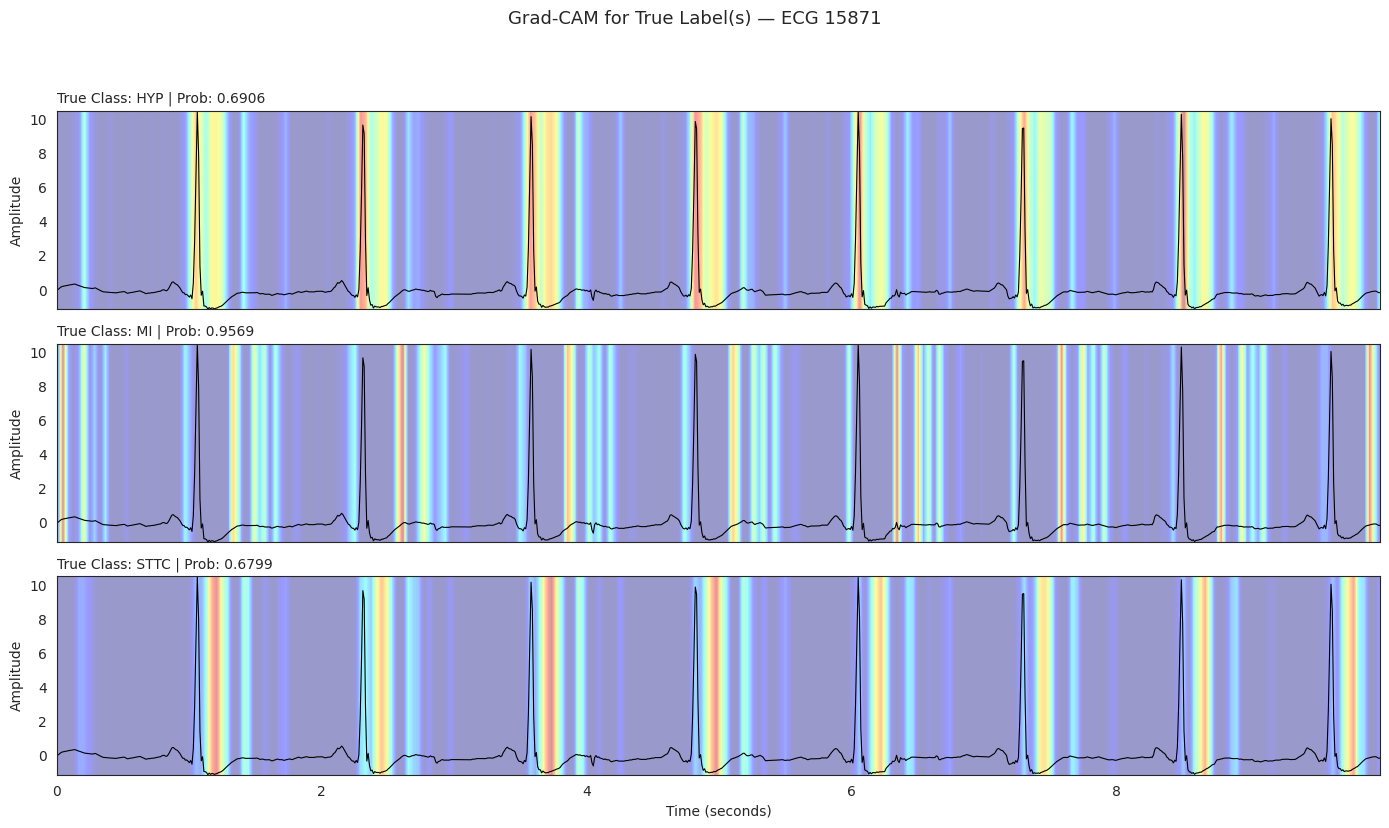

Saved: figures/18_gradcam_true_classes_ecg_15871.png

GRAD-CAM EXPLANATION SUMMARY
ECG ID: 15871 | split: test | idx: 1655
True: ['HYP', 'MI', 'STTC'] | Pred: ['HYP', 'MI', 'STTC'] | threshold: 0.5
Target layer: se_attention


In [ ]:
# =============================================================================
# Model Explainability
# Grad-CAM for Multi-Branch / Multi-Input ECG Model
# =============================================================================

import os
import numpy as np
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt

# -----------------------------------------------------------------------------
# Config
# -----------------------------------------------------------------------------
FIGURES_DIR = "figures"
os.makedirs(FIGURES_DIR, exist_ok=True)

DESIRED_ECG_ID = 15871
TARGET_LAYER = "se_attention"
THRESHOLD = 0.5


# -----------------------------------------------------------------------------
# ECG lookup 
# -----------------------------------------------------------------------------
def get_ecg_by_id(ecg_id):
    splits = {
        "train": (X_train, patient_data_train, y_train, masks["train"]),
        "val":   (X_val,   patient_data_val,   y_val,   masks["val"]),
        "test":  (X_test,  patient_data_test,  y_test,  masks["test"]),
    }

    for split_name, (X_split, patient_split, y_split, mask) in splits.items():
        split_ids = df_meta.loc[mask, "ecg_id"].to_numpy()

        if len(split_ids) != len(X_split):
            raise ValueError(
                f"Alignment problem in '{split_name}': "
                f"{len(split_ids)} ids vs {len(X_split)} signals."
            )

        matches = np.where(split_ids == ecg_id)[0]
        if len(matches):
            idx = int(matches[0])
            return {
                "ecg_id": int(split_ids[idx]),
                "split": split_name,
                "index": idx,
                "signal": X_split[idx:idx + 1],
                "patient": patient_split[idx:idx + 1],
                "true_vec": y_split[idx],
            }

    fold = df_meta.loc[df_meta["ecg_id"] == ecg_id, "strat_fold"]
    if len(fold):
        raise ValueError(
            f"ecg_id {ecg_id} exists (strat_fold={fold.values[0]}) but was "
            f"filtered out before train/val/test arrays were built."
        )
    raise ValueError(f"ecg_id {ecg_id} not found in df_meta.")


# -----------------------------------------------------------------------------
# Grad-CAM
# -----------------------------------------------------------------------------
class GradCAM1D:
    """Grad-CAM for the temporal branch of a multi-input ECG model."""

    def __init__(self, model: keras.Model, target_layer_name: str = "se_attention"):
        self.model = model
        self.target_layer_name = target_layer_name

        try:
            target_layer = model.get_layer(target_layer_name)
        except ValueError:
            available = "\n".join(l.name for l in model.layers)
            raise ValueError(
                f"Layer '{target_layer_name}' not found. Available layers:\n{available}"
            )

        self.grad_model = keras.Model(
            inputs=model.inputs,
            outputs=[target_layer.output, model.output],
        )

    def generate(self, ecg_signal, patient_vec, target_class):
        ecg_tensor = tf.convert_to_tensor(ecg_signal, dtype=tf.float32)
        patient_tensor = tf.convert_to_tensor(patient_vec, dtype=tf.float32)

        with tf.GradientTape() as tape:
            feature_map, predictions = self.grad_model(
                [ecg_tensor, patient_tensor], training=False
            )
            score = predictions[:, target_class]

        grads = tape.gradient(score, feature_map)
        if grads is None:
            raise RuntimeError(f"No gradients for layer '{self.target_layer_name}'.")

        weights = tf.reduce_mean(grads, axis=1)
        cam = tf.nn.relu(tf.reduce_sum(feature_map * weights[:, tf.newaxis, :], axis=-1))
        cam = cam[0].numpy()

        # Resample to original signal length + normalize to [0, 1]
        original_length = ecg_signal.shape[1]
        cam = np.interp(np.linspace(0, len(cam) - 1, original_length), np.arange(len(cam)), cam)
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam


# -----------------------------------------------------------------------------
# Shared plotting helper
# -----------------------------------------------------------------------------
def plot_gradcam_grid(gradcam, signal, patient, class_indices, t, lead_trace,
                       titles, suptitle, save_path):
    n = len(class_indices)
    fig, axes = plt.subplots(n, 1, figsize=(14, 2.8 * n), sharex=True)
    axes = [axes] if n == 1 else axes

    for ax, class_idx, title in zip(axes, class_indices, titles):
        cam = gradcam.generate(signal, patient, target_class=class_idx)

        ax.plot(t, lead_trace, color="black", linewidth=0.8, label="Lead II")
        ax.imshow(
            cam[np.newaxis, :],
            extent=[t[0], t[-1], lead_trace.min(), lead_trace.max()],
            aspect="auto", cmap="jet", alpha=0.40, origin="lower",
        )
        ax.set_title(title, fontsize=10, loc="left")
        ax.set_ylabel("Amplitude")

    axes[-1].set_xlabel("Time (seconds)")
    fig.suptitle(suptitle, fontsize=13)
    plt.tight_layout(rect=[0, 0, 1, 0.94])
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Saved: {save_path}")


# -----------------------------------------------------------------------------
# Run
# -----------------------------------------------------------------------------
gradcam = GradCAM1D(model=model, target_layer_name=TARGET_LAYER)

ecg_data = get_ecg_by_id(DESIRED_ECG_ID)
signal, patient, true_vec = ecg_data["signal"], ecg_data["patient"], ecg_data["true_vec"]
idx, ecg_id, split = ecg_data["index"], ecg_data["ecg_id"], ecg_data["split"]

print(f"ECG {ecg_id} | split={split} | idx={idx} | signal={signal.shape} | patient={patient.shape}")

true_labels = [classes[i] for i, v in enumerate(true_vec) if v == 1] or ["(none)"]

pred_prob = model.predict([signal, patient], verbose=0)[0]
pred_vec = (pred_prob >= THRESHOLD).astype(int)
pred_labels = [classes[i] for i, v in enumerate(pred_vec) if v == 1] or ["(none)"]

print(f"True: {true_labels} | Pred: {pred_labels} | threshold={THRESHOLD}")
for i, cls in enumerate(classes):
    marker = ("  <-- TRUE" if cls in true_labels else "") + ("  <-- PRED" if cls in pred_labels else "")
    print(f"{cls:10s}: {pred_prob[i]:.4f}{marker}")

# Time axis + Lead II
t = np.arange(signal.shape[1]) / cfg.SAMPLING_RATE
lead_ii = signal[0, :, 1]

# --- Grad-CAM for every class ---
all_titles = [
    f"Class: {cls} | Prob: {pred_prob[i]:.4f}"
    + (" | TRUE" if cls in true_labels else "")
    + (" | PREDICTED" if cls in pred_labels else "")
    for i, cls in enumerate(classes)
]
plot_gradcam_grid(
    gradcam, signal, patient, list(range(len(classes))), t, lead_ii, all_titles,
    suptitle=f"Grad-CAM — ECG {ecg_id} ({split})\nTrue: {true_labels} | Predicted: {pred_labels}",
    save_path=os.path.join(FIGURES_DIR, f"18_gradcam_ecg_{ecg_id}.png"),
)

# --- Intermediate feature maps ---
activation_model = keras.Model(inputs=model.inputs, outputs=model.get_layer(TARGET_LAYER).output)
feature_maps = activation_model.predict([signal, patient], verbose=0)[0]
print(f"Feature map shape ({TARGET_LAYER}): {feature_maps.shape}")

n_channels = min(6, feature_maps.shape[-1])
fig, axes = plt.subplots(2, 3, figsize=(14, 6))
axes = axes.flatten()
for i, ax in enumerate(axes):
    if i < n_channels:
        ax.plot(feature_maps[:, i], linewidth=0.8)
        ax.set_title(f"{TARGET_LAYER} — Channel {i}", fontsize=9)
        ax.set_xlabel("Temporal Feature Index")
        ax.set_ylabel("Activation")
    else:
        ax.axis("off")
fig.suptitle(f"Intermediate Temporal Activations\nECG {ecg_id} | {split}", fontsize=13)
plt.tight_layout(rect=[0, 0, 1, 0.93])
feature_path = os.path.join(FIGURES_DIR, f"18_feature_maps_ecg_{ecg_id}.png")
plt.savefig(feature_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved: {feature_path}")

# --- Grad-CAM for TRUE classes only ---
true_idx = [i for i, v in enumerate(true_vec) if v == 1]
if true_idx:
    true_titles = [f"True Class: {classes[i]} | Prob: {pred_prob[i]:.4f}" for i in true_idx]
    plot_gradcam_grid(
        gradcam, signal, patient, true_idx, t, lead_ii, true_titles,
        suptitle=f"Grad-CAM for True Label(s) — ECG {ecg_id}",
        save_path=os.path.join(FIGURES_DIR, f"18_gradcam_true_classes_ecg_{ecg_id}.png"),
    )

# --- Summary ---
print("\n" + "=" * 70)
print("GRAD-CAM EXPLANATION SUMMARY")
print("=" * 70)
print(f"ECG ID: {ecg_id} | split: {split} | idx: {idx}")
print(f"True: {true_labels} | Pred: {pred_labels} | threshold: {THRESHOLD}")
print(f"Target layer: {TARGET_LAYER}")
print("=" * 70)

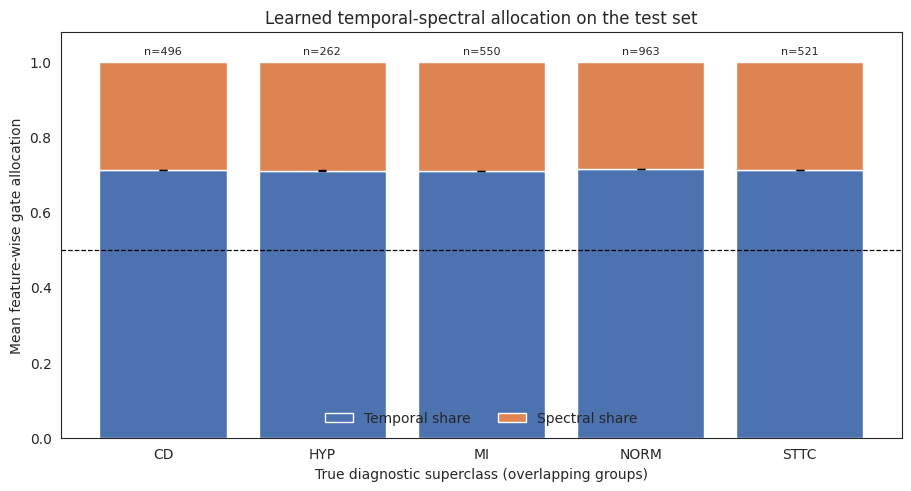

,Class,Temporal,Spectral,CI_low,CI_high,n
0,CD,0.7119,0.2881,0.7117,0.7122,496
1,HYP,0.7105,0.2895,0.7101,0.7110,262
2,MI,0.7099,0.2901,0.7097,0.7101,550
3,NORM,0.7146,0.2854,0.7144,0.7147,963
4,STTC,0.7111,0.2889,0.7108,0.7113,521


In [32]:
gate_model = keras.Model(model.inputs, model.get_layer("fusion_gate").output)
gate_values = gate_model.predict(
    [X_test, patient_data_test],
    batch_size=cfg.BATCH_SIZE,
    verbose=0,
)
temporal_share_per_record = gate_values.mean(axis=1)

rng = np.random.default_rng(SEED)
rows = []
for c, cls in enumerate(classes):
    values = temporal_share_per_record[y_test[:, c] == 1]
    if values.size == 0:
        continue
    boot_means = np.array([
        rng.choice(values, size=values.size, replace=True).mean()
        for _ in range(2000)
    ])
    lo, hi = np.quantile(boot_means, [0.025, 0.975])
    rows.append({
        "Class": cls,
        "Temporal": values.mean(),
        "Spectral": 1.0 - values.mean(),
        "CI_low": lo,
        "CI_high": hi,
        "n": values.size,
    })

gate_df = pd.DataFrame(rows)
x = np.arange(len(gate_df))
fig, ax = plt.subplots(figsize=(9, 4.8), constrained_layout=True)
ax.bar(x, gate_df["Temporal"], color="#4C72B0", label="Temporal share")
ax.bar(x, gate_df["Spectral"], bottom=gate_df["Temporal"], color="#DD8452", label="Spectral share")

yerr = np.vstack([
    gate_df["Temporal"] - gate_df["CI_low"],
    gate_df["CI_high"] - gate_df["Temporal"],
])
ax.errorbar(x, gate_df["Temporal"], yerr=yerr, fmt="none", ecolor="black", capsize=3, linewidth=1)
for i, row in gate_df.iterrows():
    ax.text(i, 1.015, f"n={int(row['n'])}", ha="center", va="bottom", fontsize=8)

ax.axhline(0.5, color="black", linestyle="--", linewidth=0.9)
ax.set_xticks(x, gate_df["Class"])
ax.set_ylim(0, 1.08)
ax.set_ylabel("Mean feature-wise gate allocation")
ax.set_xlabel("True diagnostic superclass (overlapping groups)")
ax.set_title("Learned temporal-spectral allocation on the test set")
ax.legend(frameon=False, ncol=2, loc="lower center")

plt.show()
display(gate_df.round(4))